# Personalization & control

DreamBooth · B-LoRA · ZipLoRA

ControlNet · IP-Adapter

**Takeaway:** Deep Generative Models · Seminar 10 · MIPT / YSDA · Autumn 2026 · 26 November 2026



## The shared denoising task

1. Encode a training image: $z_0=E_{\rm VAE}(x)$.

2. Sample a time $t$ and Gaussian noise $\epsilon$; construct $z_t$.

3. Give the denoiser the noisy latent, text $c$ and extra condition $u$.

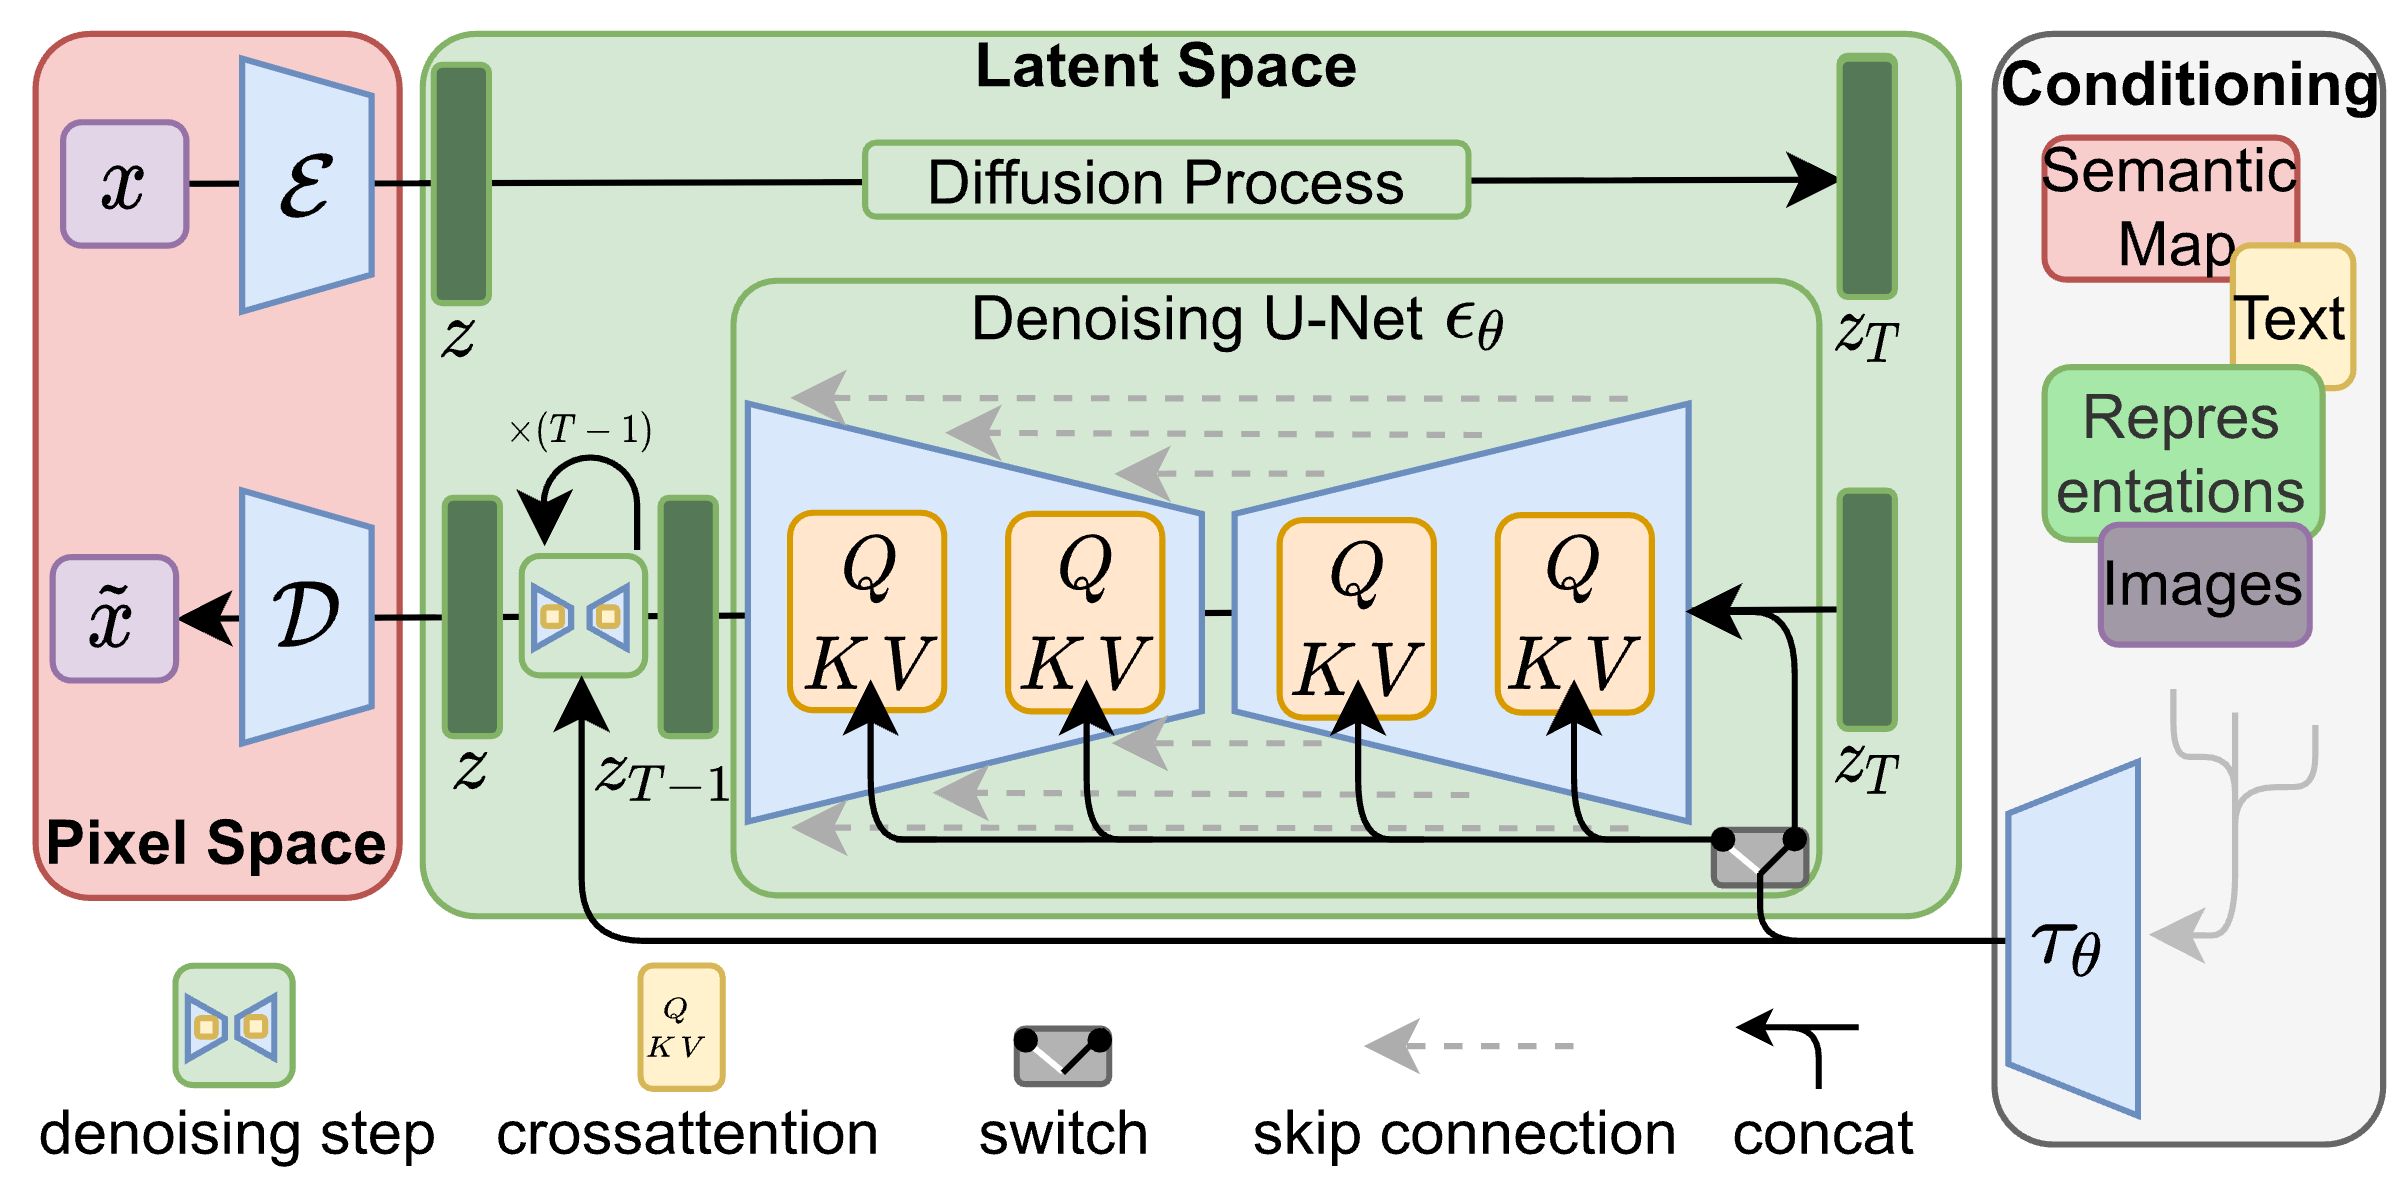

*Original LDM architecture: compression, diffusion and conditioning.*

$$
z_t=\sqrt{\bar\alpha_t}z_0+\sqrt{1-\bar\alpha_t}\epsilon,\qquad \epsilon\sim\mathcal N(0,I)
$$

$$
\mathcal L_{\mathrm{noise}}=\mathbb E\|\epsilon-\epsilon_{\theta,\phi}(z_t,t,c,u)\|_2^2
$$

<b>What the network sees:</b> a corrupted latent and the conditions.

<b>What the loss knows:</b> the exact noise sampled for that example.

<b>What changes today:</b> which weights learn and where extra conditions enter.

**Takeaway:** Training target: the sampled noise. The methods differ in the condition u and the parameters allowed to learn.

Sources: [Rombach et al. · Latent Diffusion](https://arxiv.org/abs/2112.10752) · [Diffusers v0.35.1 · DreamBooth](https://huggingface.co/docs/diffusers/v0.35.1/en/training/dreambooth)


## LoRA: a small trainable weight update

For an SD attention layer, typical targets are

<code>to_q, to_k, to_v, to_out</code>.



Only A and B learn; r is the update rank.

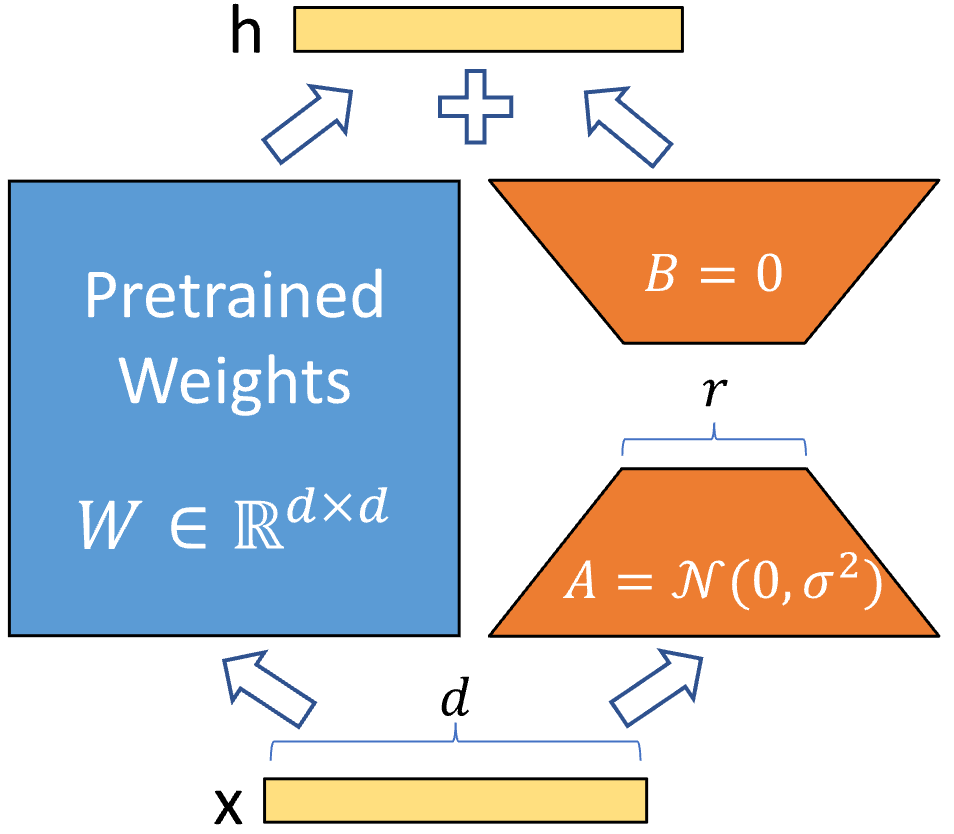

$$
W=W_0+\frac{\alpha}{r}BA
$$

$$
y=W_0x+\frac{\alpha}{r}B(Ax)
$$

**Takeaway:** α/r is the training normalization. An extra adapter scale can adjust the learned update at sampling.

Sources: [Hu et al. · LoRA](https://arxiv.org/abs/2106.09685)


## DreamBooth: bind an identifier to one subject

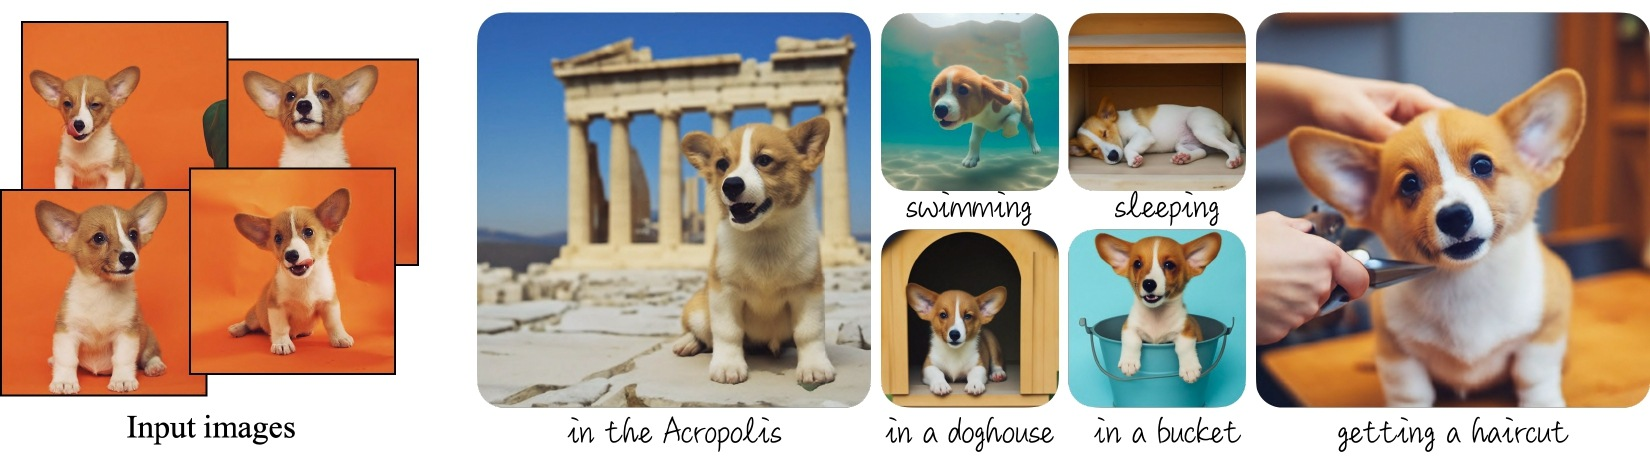

**Takeaway:** A few subject photographs teach a prompt such as “a [V] dog” to refer to that subject.

Sources: [Ruiz et al. · DreamBooth](https://arxiv.org/abs/2208.12242) · [DreamBooth · project](https://dreambooth.github.io/)


## DreamBooth: the authors’ training pipeline

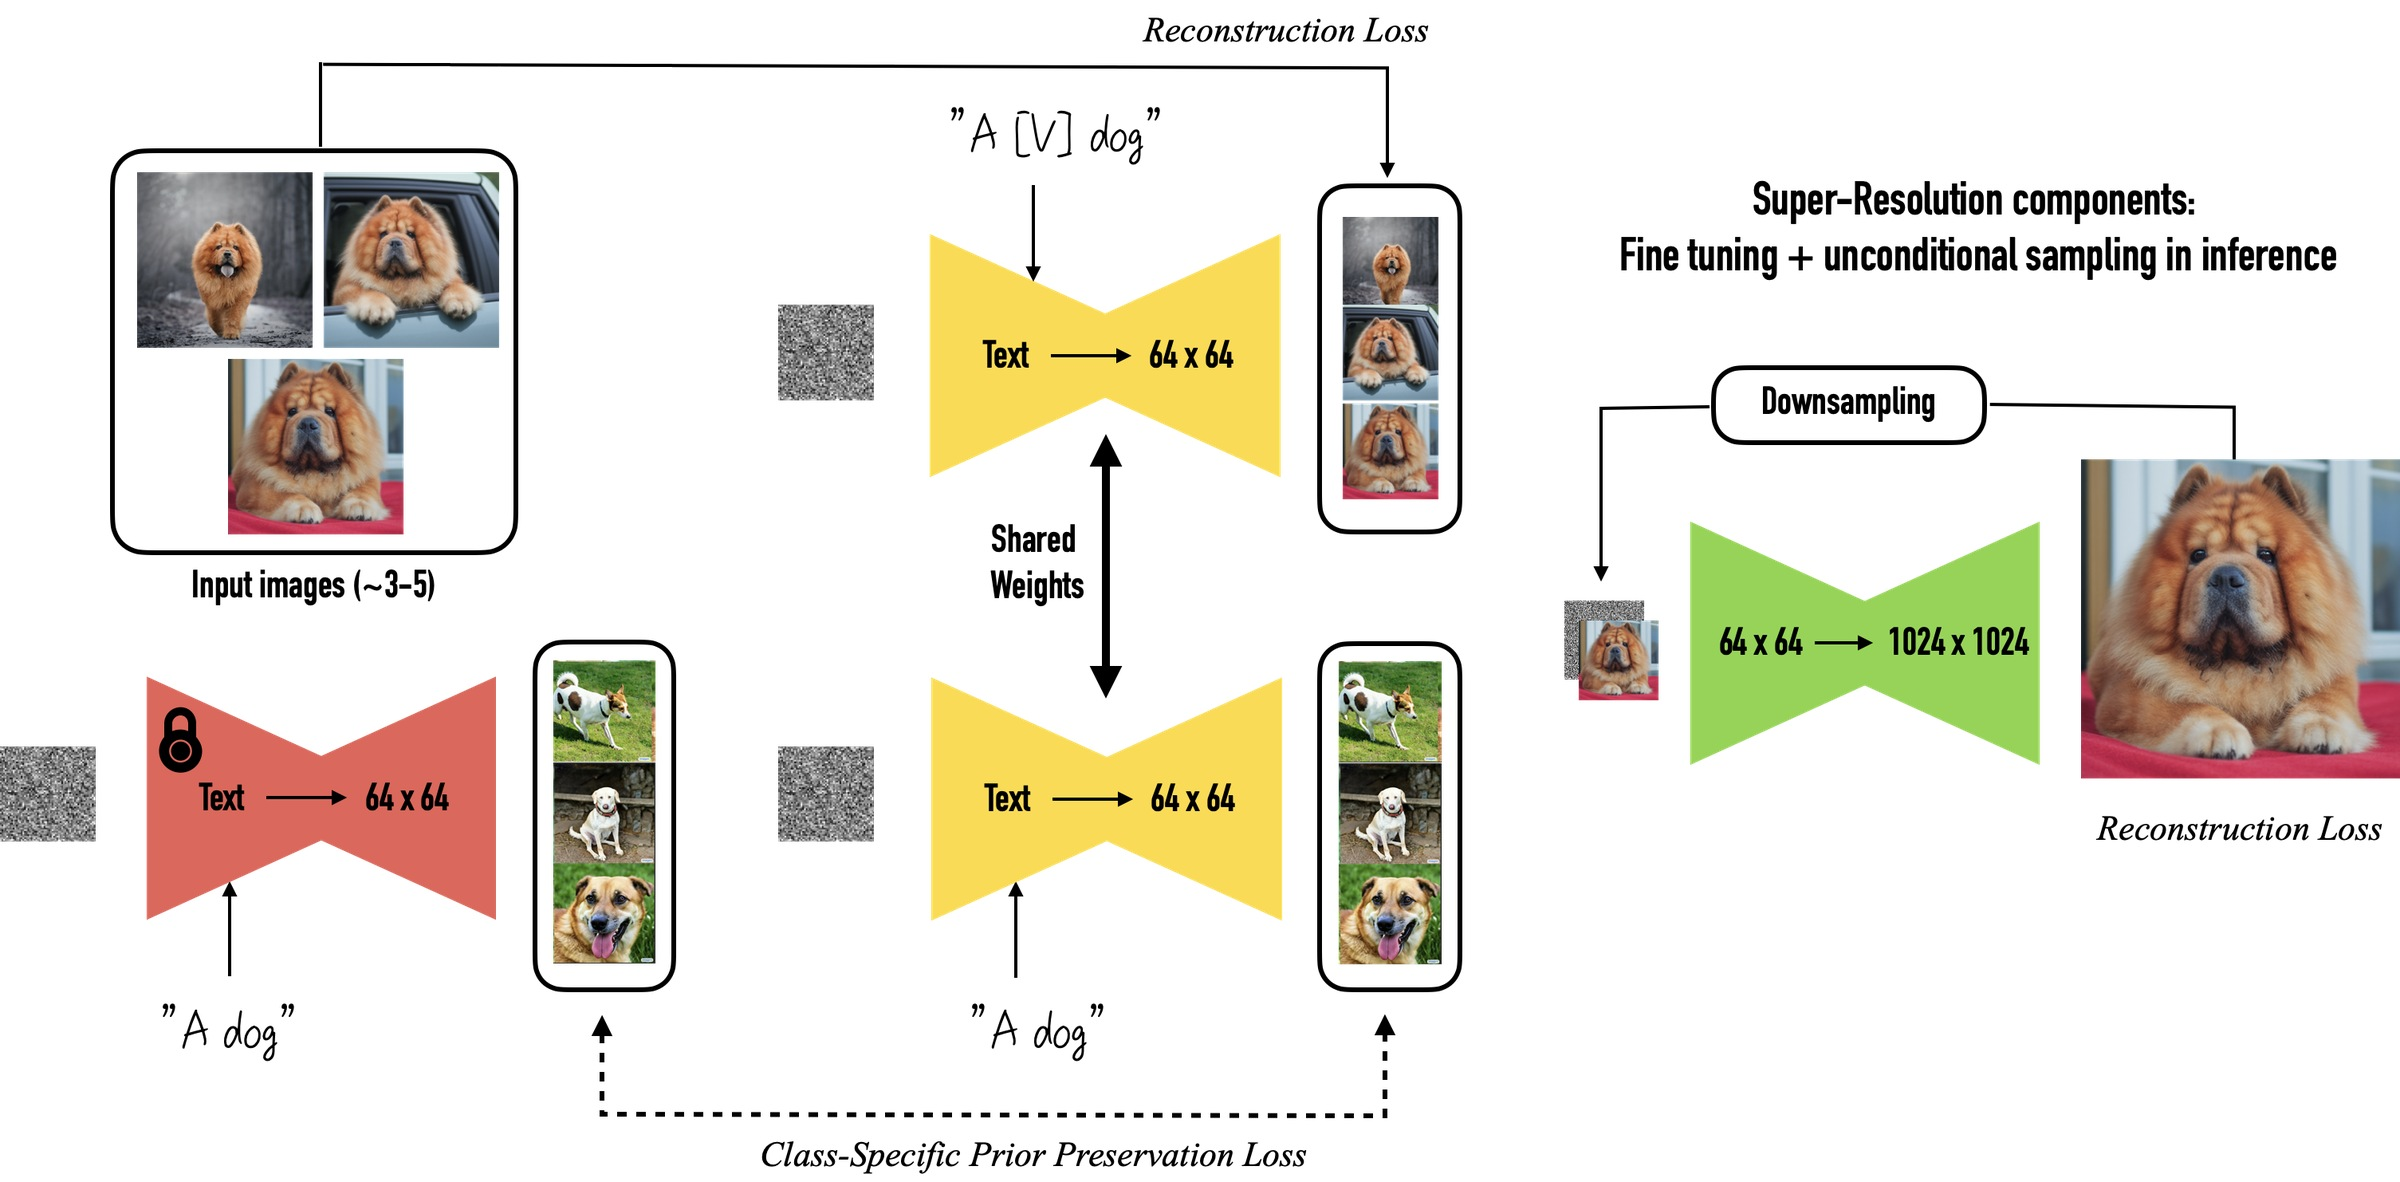

**Takeaway:** Top/bottom: subject/class training. Right: the original Imagen super-resolution stage, absent from latent SD.

Sources: [Ruiz et al. · DreamBooth v1 · Fig. 4](https://arxiv.org/pdf/2208.12242v1) · [DreamBooth · project](https://dreambooth.github.io/)


## DreamBooth loss in a latent SD implementation

$\phi$: trainable U-Net weights for full fine-tuning, or LoRA matrices A and B.

Each branch predicts its own sampled noise.

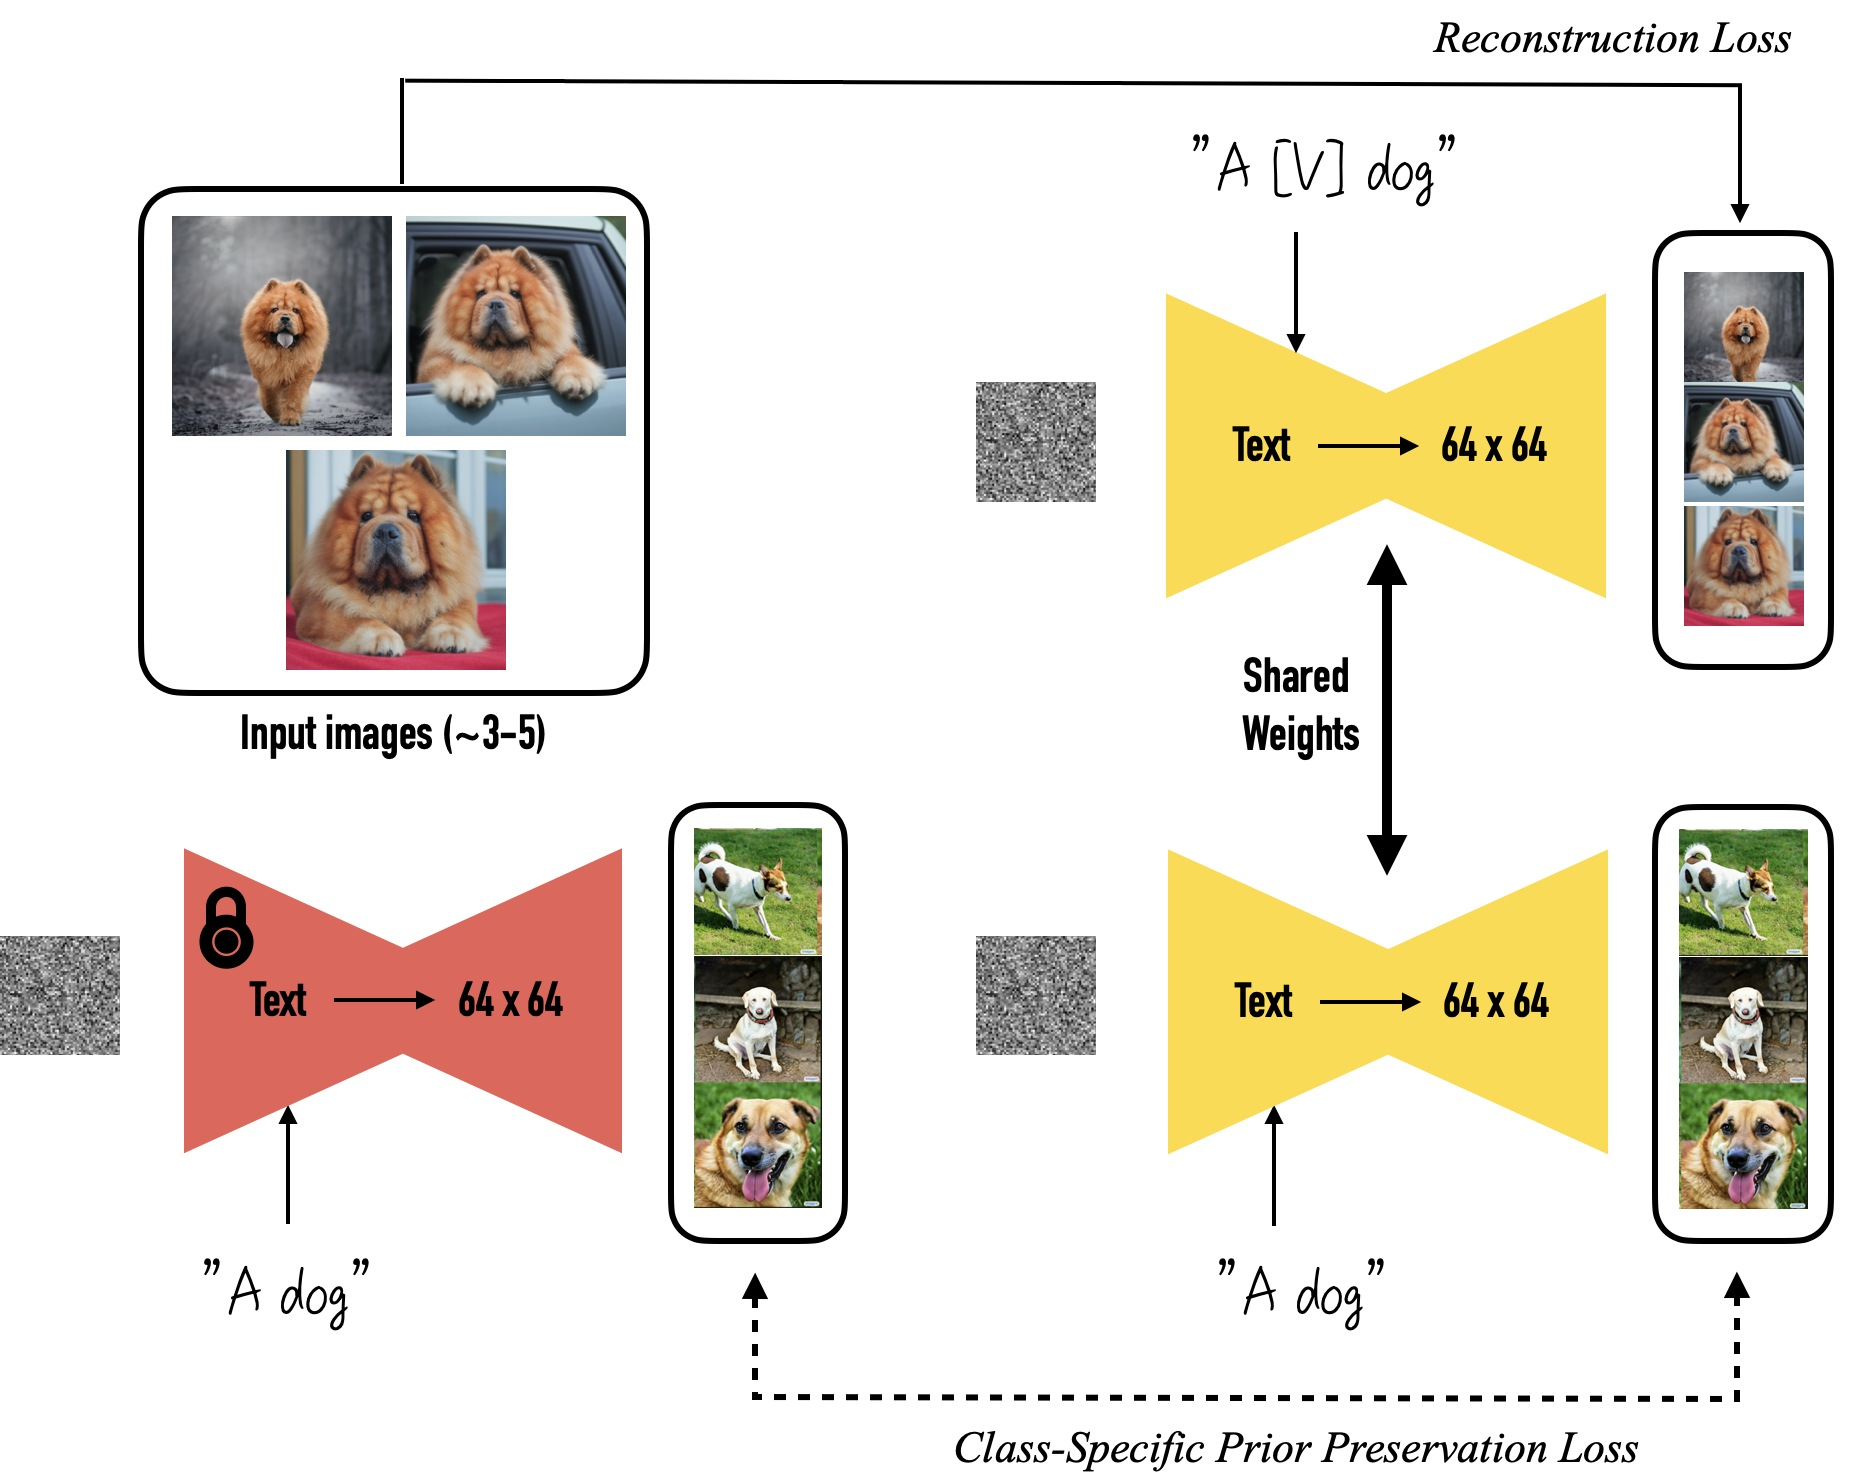

*Original Imagen training branches; below, the equivalent loss structure for latent SD.*

$$
\mathcal L_{\rm DB}=\mathcal L_{\rm subject}+\lambda_{\rm prior}\mathcal L_{\rm class}
$$

$$
\mathcal L_{\rm subject}=\mathbb E\|\epsilon-\epsilon_\phi(z_t,t,c_{[V]})\|_2^2
$$

$$
\mathcal L_{\rm class}=\mathbb E\|\epsilon^{\rm cl}-\epsilon_\phi(z^{\rm cl}_{t},t,c_{\rm class})\|_2^2
$$

<b>Subject branch:</b> photos of one dog, with “a [V] dog”.

<b>Class branch:</b> base-model dog images, with “a dog”.

The class term helps preserve the general meaning and diversity of “dog”.

**Takeaway:** Prior preservation rehearses the general class while the subject branch learns the instance.

Sources: [DreamBooth · project](https://dreambooth.github.io/) · [Diffusers v0.35.1 · DreamBooth](https://huggingface.co/docs/diffusers/v0.35.1/en/training/dreambooth)


## DreamBooth sampling and evaluation

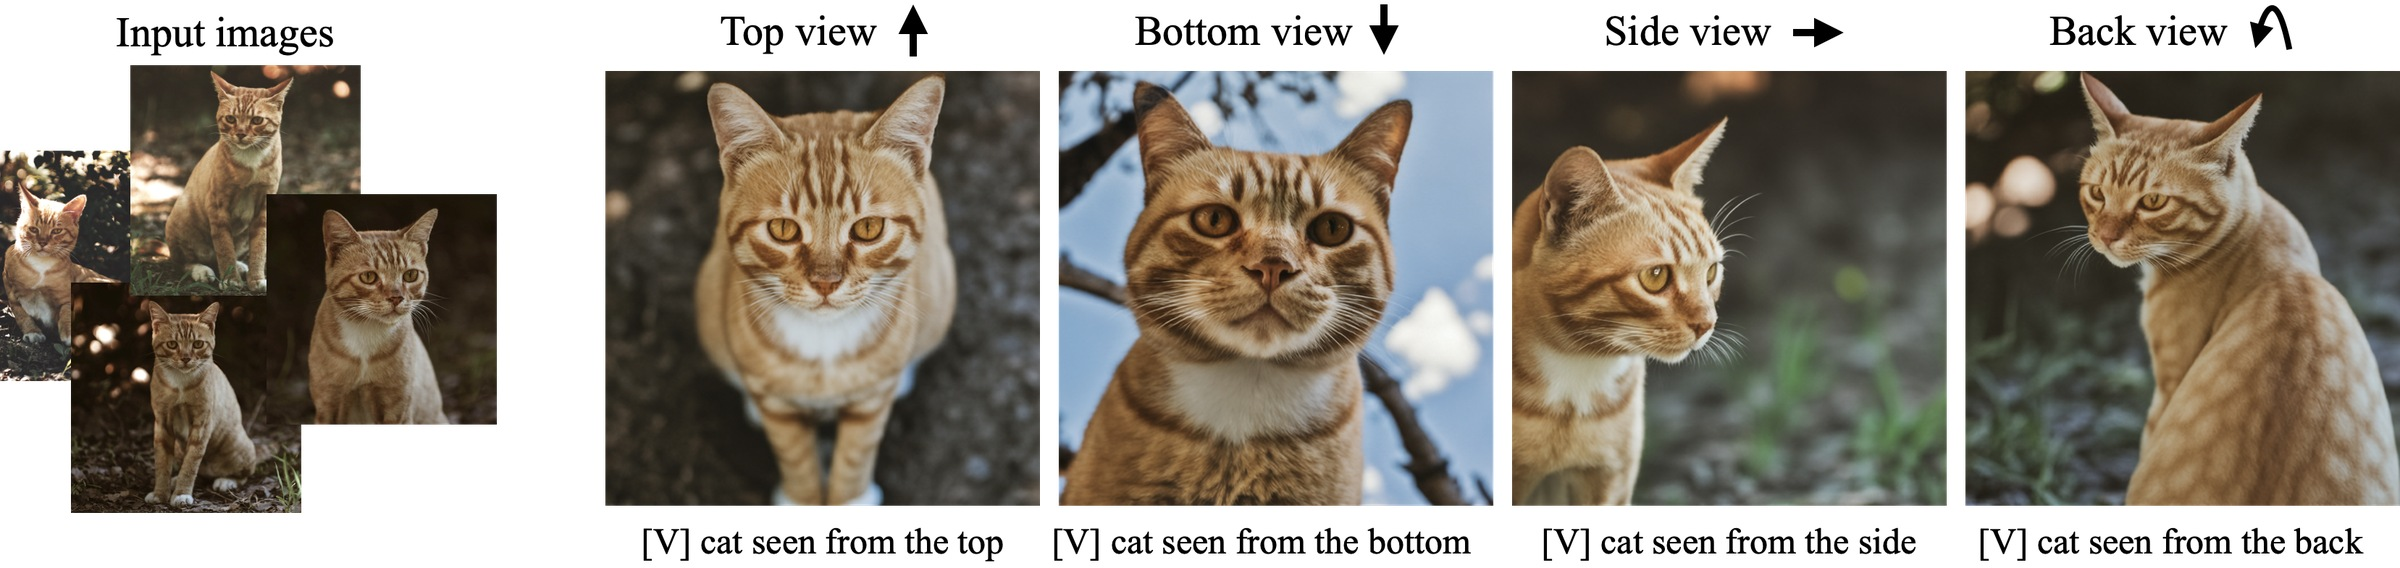

**Takeaway:** Author examples: the subject identifier stays fixed while the text requests a new viewpoint.

Sources: [DreamBooth · project](https://dreambooth.github.io/) · [Ruiz et al. · DreamBooth](https://arxiv.org/abs/2208.12242)


## B-LoRA: probe where text changes the image

$\hat p$ enters only the selected group.

The other groups receive $p$.



$W^4$: <code>up_blocks.0.attentions.0</code>

$W^5$: <code>up_blocks.0.attentions.1</code>



Both belong to SDXL Up Block 0.

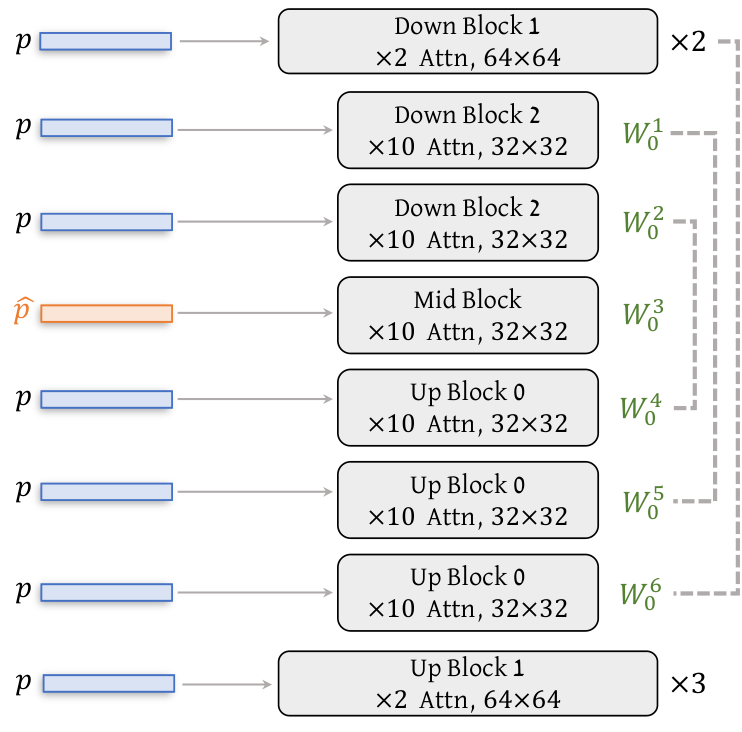

**Takeaway:** Send the alternative prompt to one attention group; keep the original prompt everywhere else.

Sources: [Frenkel et al. · B-LoRA](https://arxiv.org/abs/2403.14572)


## B-LoRA: content and color respond differently

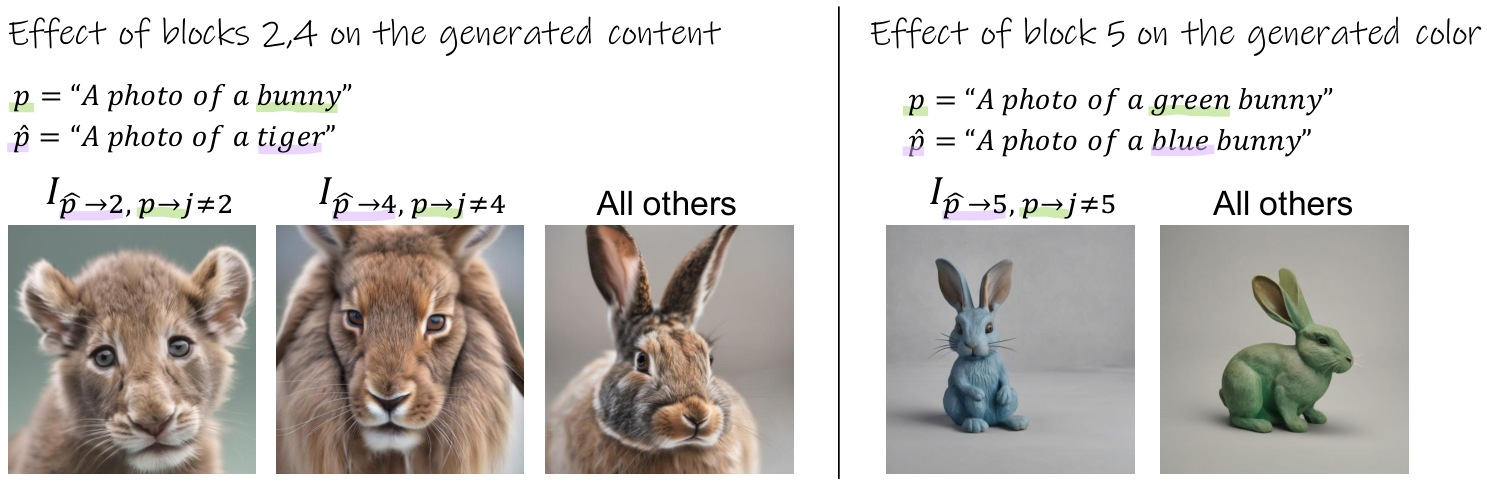

**Takeaway:** Only group i receives the alternative prompt. Groups 2/4 change the object; group 5 changes color, a style proxy.

Sources: [Frenkel et al. · B-LoRA](https://arxiv.org/abs/2403.14572)


## B-LoRA: learn two selected SDXL blocks

1. Take one reference image and the generic prompt “A [v]”.

2. Encode the image, choose a noise level and add known noise.

3. Train LoRA in SDXL groups 4 and 5 jointly; freeze all other groups.

4. At sampling, keep the content group, the style group, or both.

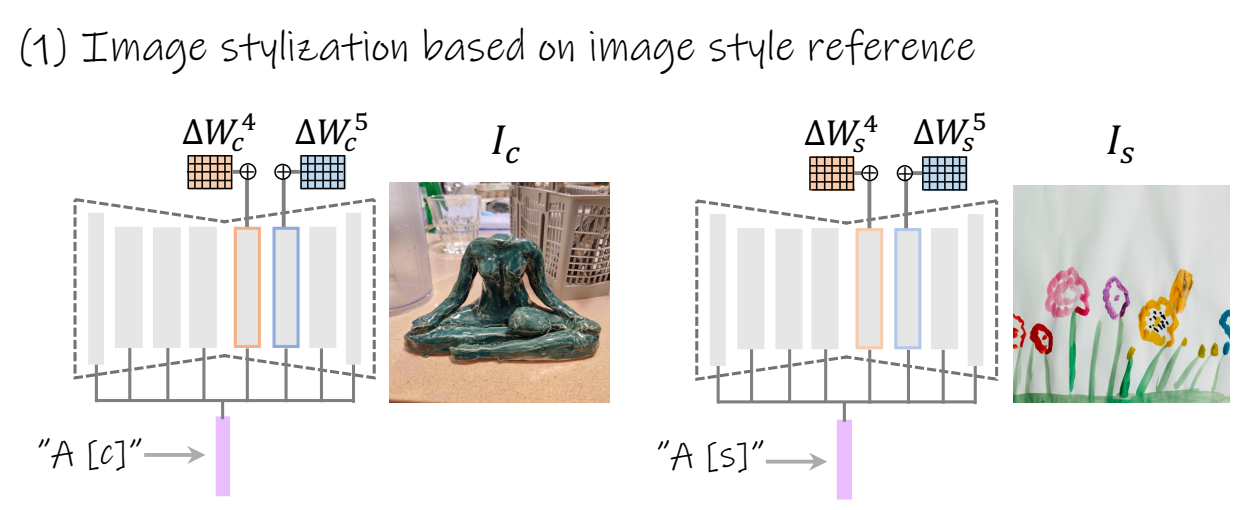

*Original scheme: each reference gets its own pair of trained groups.*

$$
\min_{\Delta W^4,\Delta W^5}\ \mathbb E\|\epsilon-\epsilon_{W_0+\Delta W^4+\Delta W^5}(z_t,t,c_{[v]})\|_2^2
$$

**Takeaway:** One denoising loss, with no separate style labels. Published recipe: rank 64 and 1,000 updates.

Sources: [Frenkel et al. · B-LoRA](https://arxiv.org/abs/2403.14572) · [B-LoRA · official code](https://github.com/yardenfren1996/B-LoRA)


## B-LoRA: recombine content and style

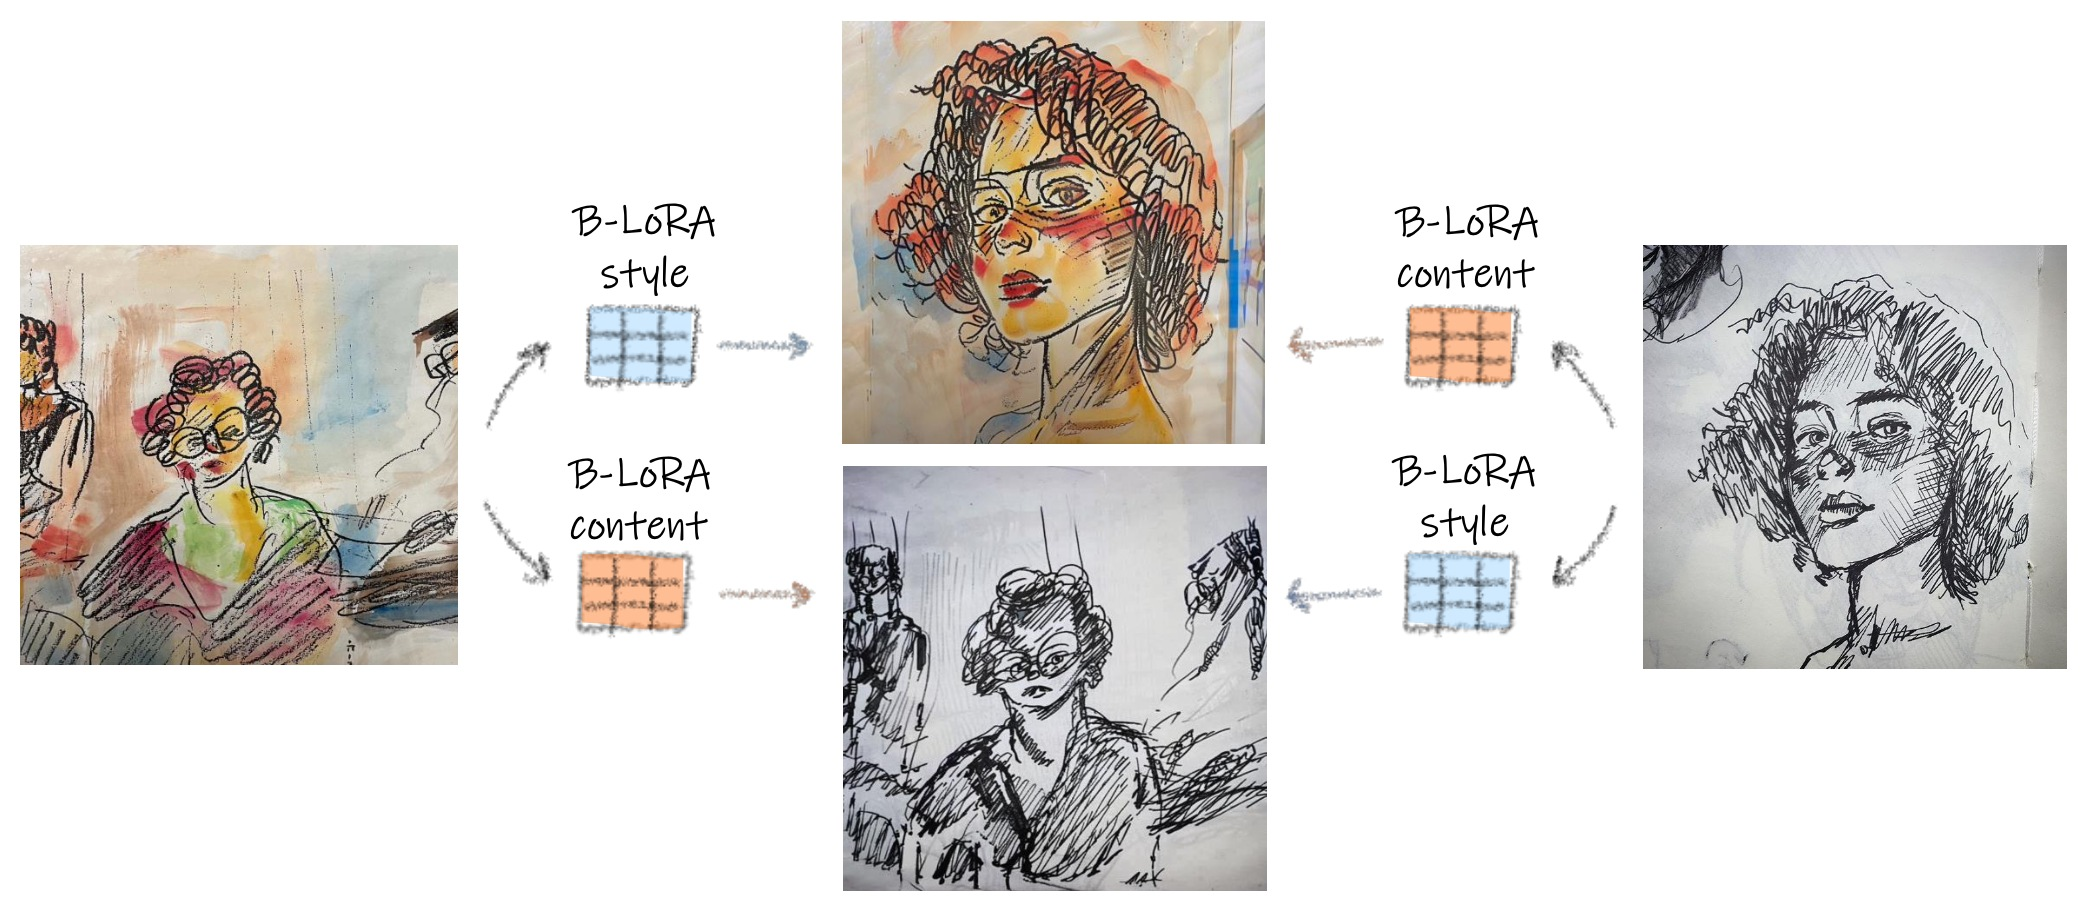

$$
W=W_0+\Delta W^4_{\rm content\ image}+\Delta W^5_{\rm style\ image}
$$

**Takeaway:** Author examples: keep the content group from one reference and the style group from the other.

Sources: [Frenkel et al. · B-LoRA](https://arxiv.org/abs/2403.14572) · [B-LoRA · official code](https://github.com/yardenfren1996/B-LoRA)


## B-LoRA: why choose groups 4 and 5?

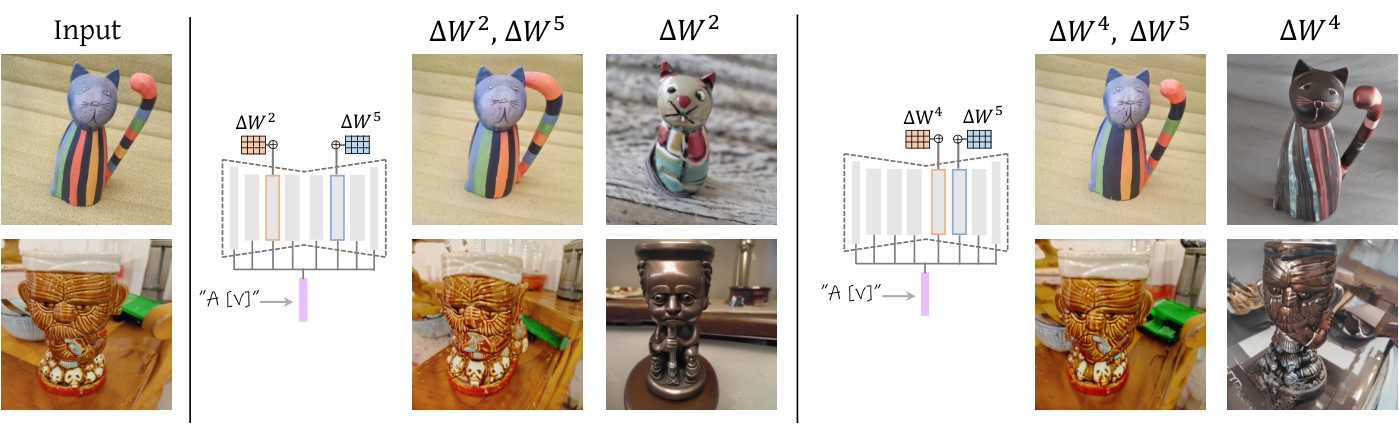

**Takeaway:** Compare reconstruction with both groups against content-only generation after dropping the style group.

Sources: [Frenkel et al. · B-LoRA](https://arxiv.org/abs/2403.14572)


## B-LoRA: reading the original scheme

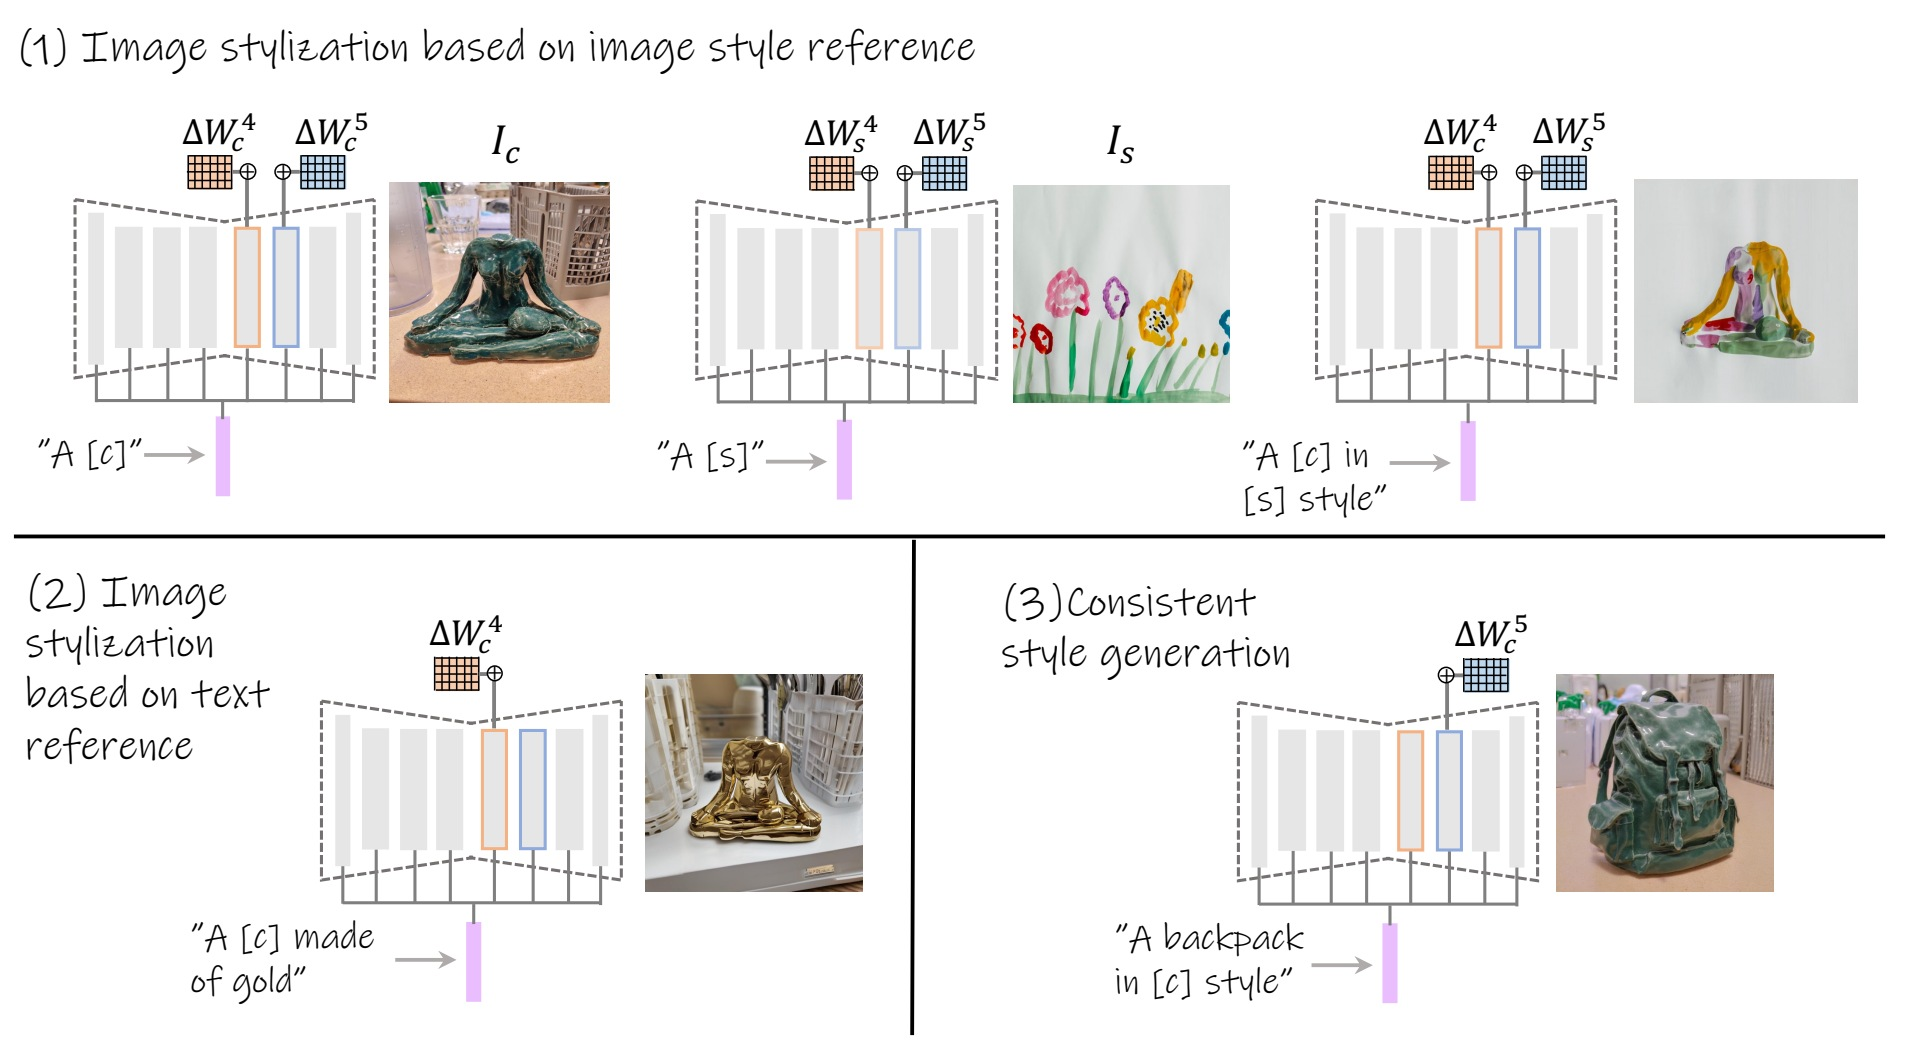

**Takeaway:** Top: combine content and style references. Bottom left: text-defined style. Bottom right: reuse a learned style.

Sources: [B-LoRA · official code](https://github.com/yardenfren1996/B-LoRA)


## Why adding two LoRAs can fail

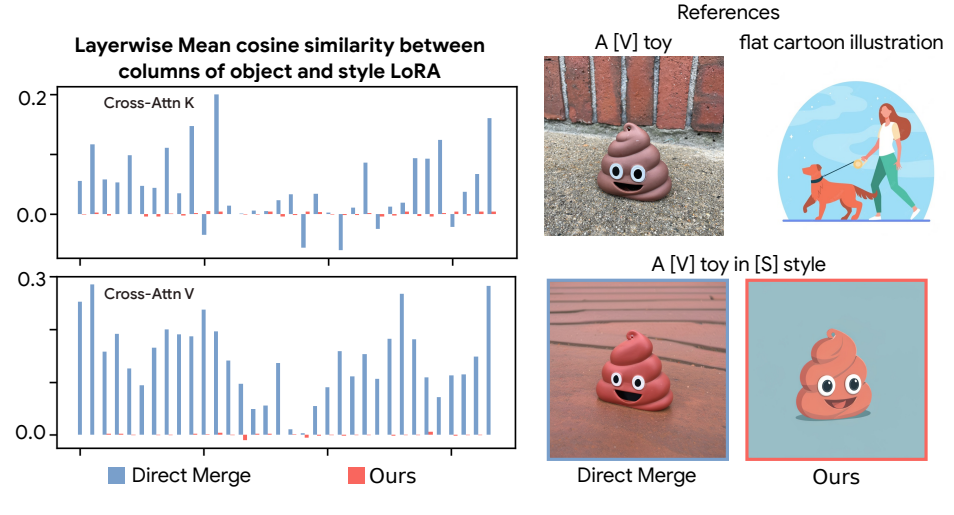

**Takeaway:** Blue: direct merge. Red: ZipLoRA, with reported column similarity near zero in this example. Right: improved stylization.

Sources: [Shah et al. · ZipLoRA](https://arxiv.org/abs/2311.13600)


## ZipLoRA: learn how to merge existing updates

Each layer has two frozen updates $\Delta W_c$ and $\Delta W_s$.

Learn $m_c,m_s$: one coefficient per input column, not per rank component.

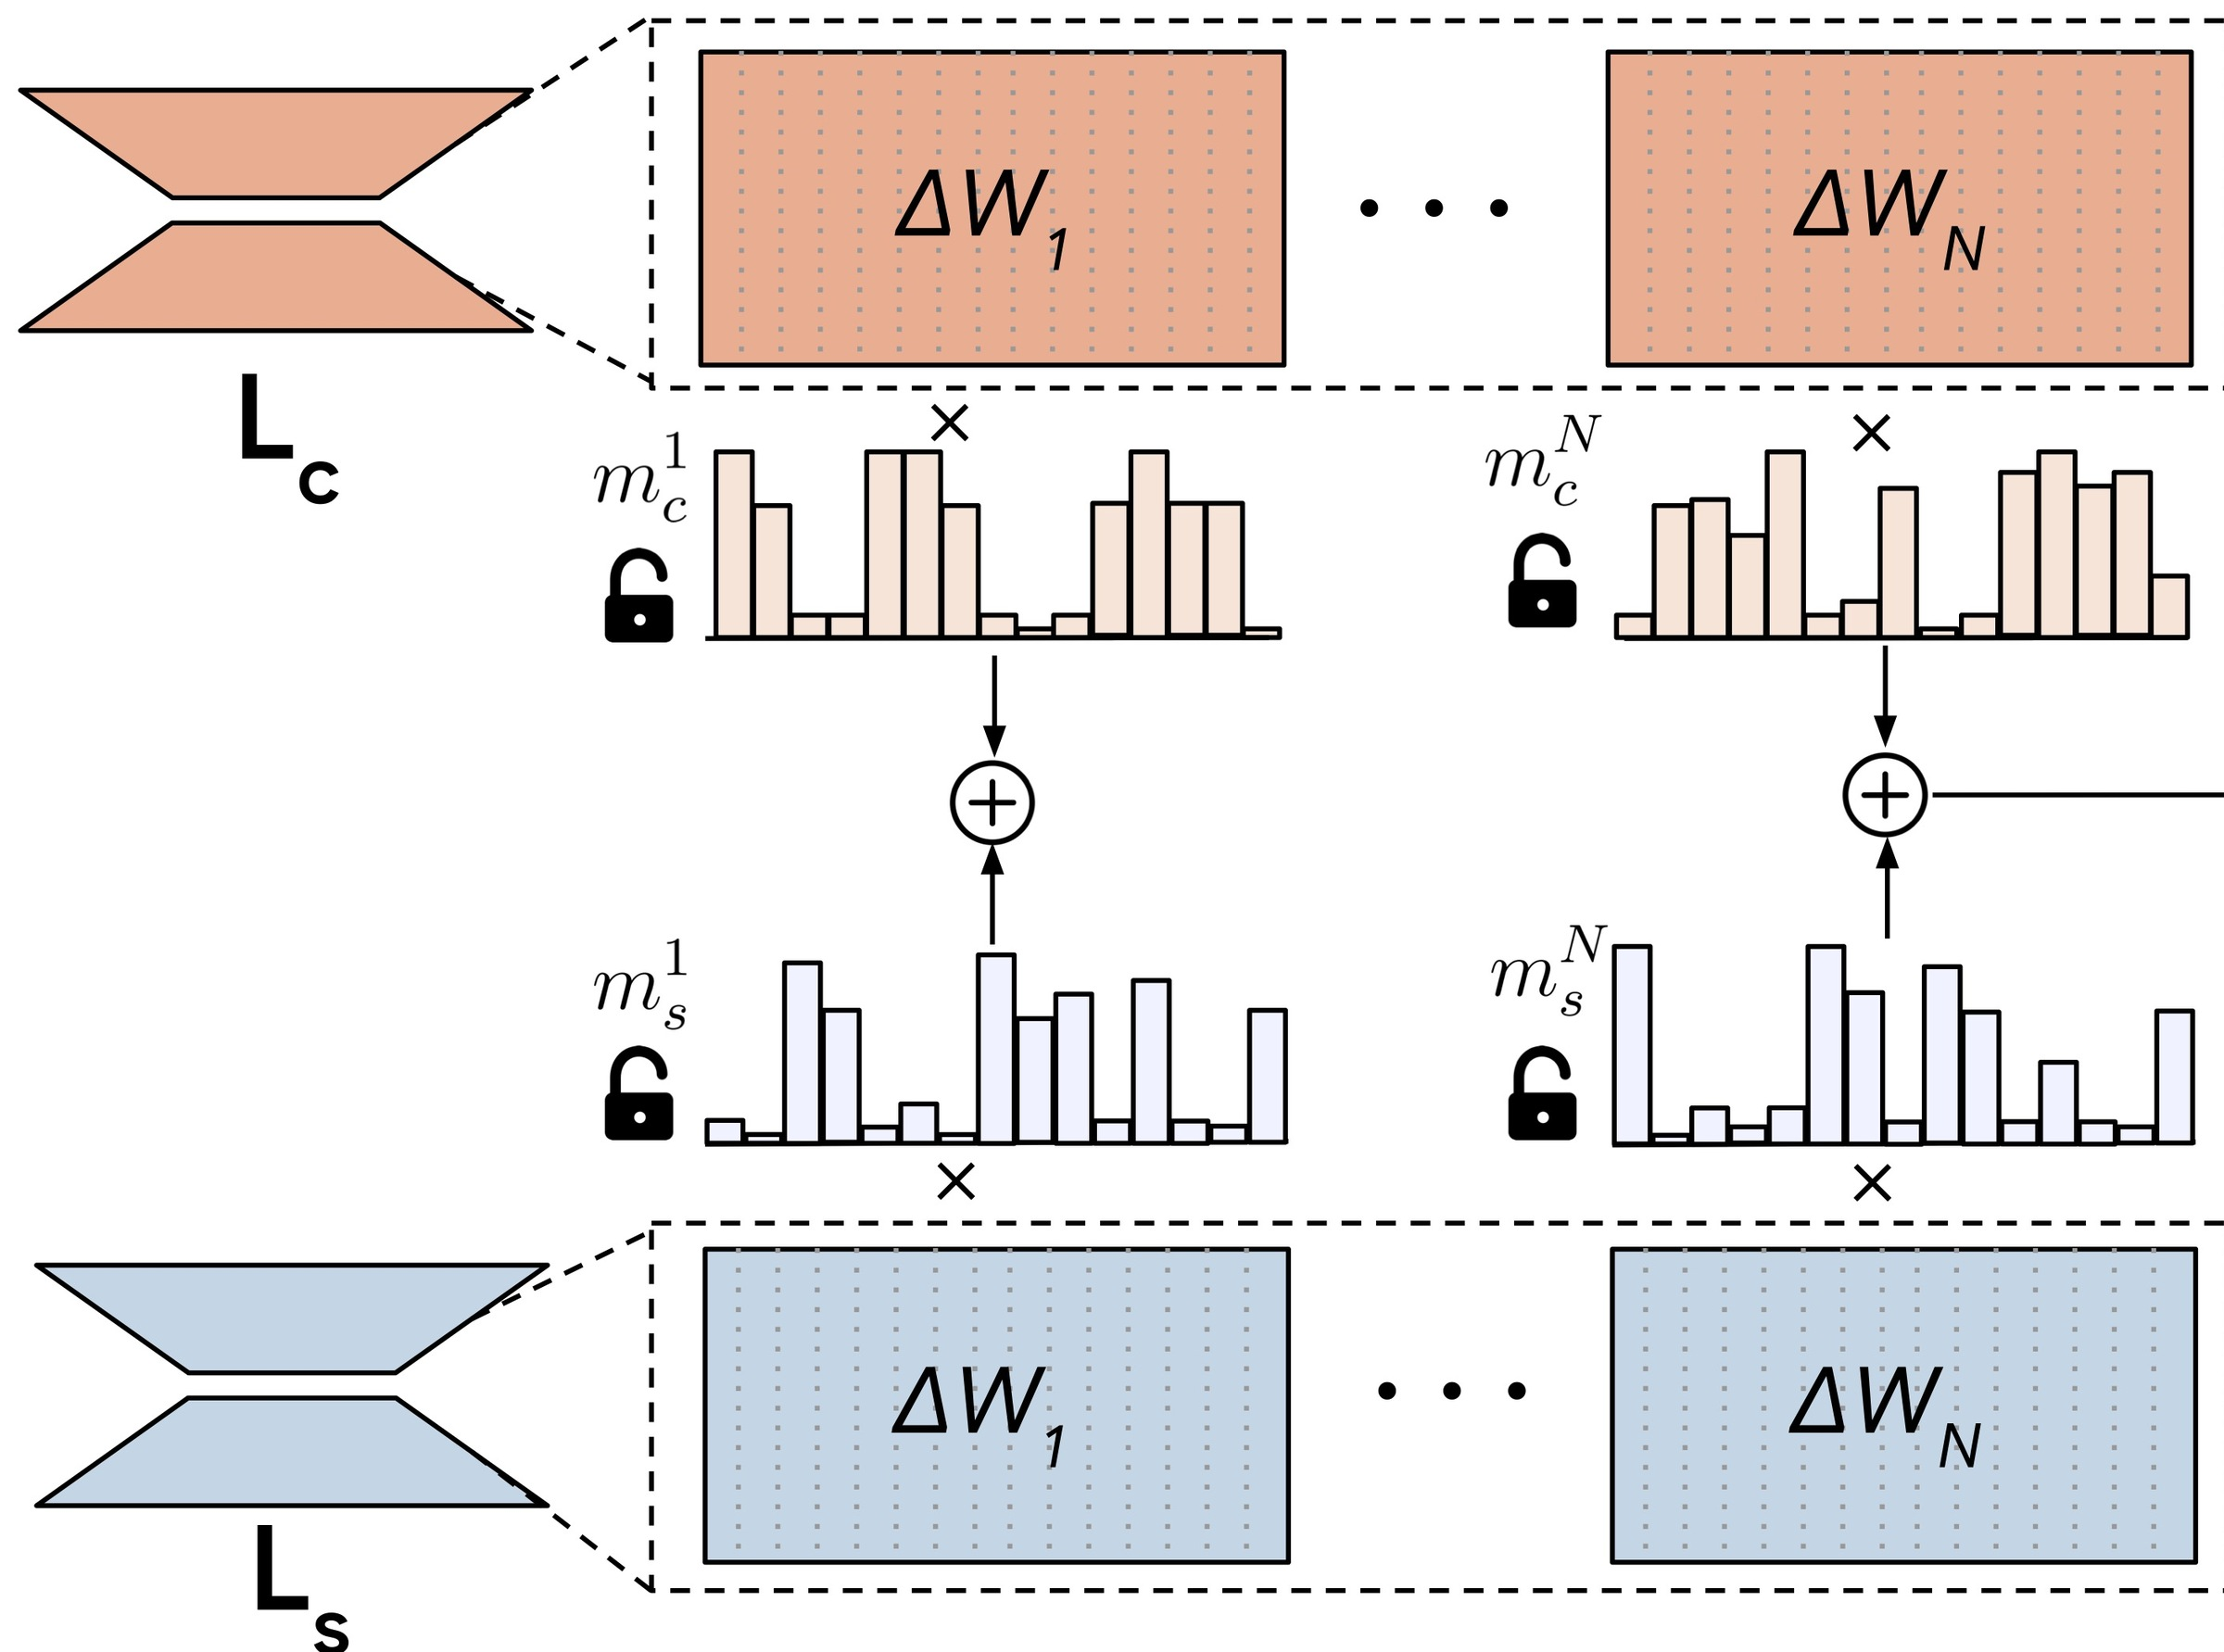

*Left part of the authors’ scheme: weighted columns and their sum.*

$$
\Delta W_m=\Delta W_c\operatorname{diag}(m_c)+\Delta W_s\operatorname{diag}(m_s)
$$

$$
\Delta W_m[:,j]=m_{c,j}\Delta W_c[:,j]+m_{s,j}\Delta W_s[:,j]
$$

Example column: $m_{c,j}=1,\ m_{s,j}=0$ keeps only the subject update.

Another column can retain style instead. The original A and B matrices stay fixed.

**Takeaway:** Start with all coefficients equal to 1: direct merge. Optimize only these coefficients to retain both concepts.

Sources: [Shah et al. · ZipLoRA v2 · Eq. 2–3](https://arxiv.org/html/2311.13600v2#S3)


## ZipLoRA training: preserve both original behaviors

$D$: base denoiser; $L_c,L_s$: frozen LoRAs; $L_m$: their learned merge.

$(x_c,p_c)$ and $(x_s,p_s)$: subject/style noisy latents and text conditions.

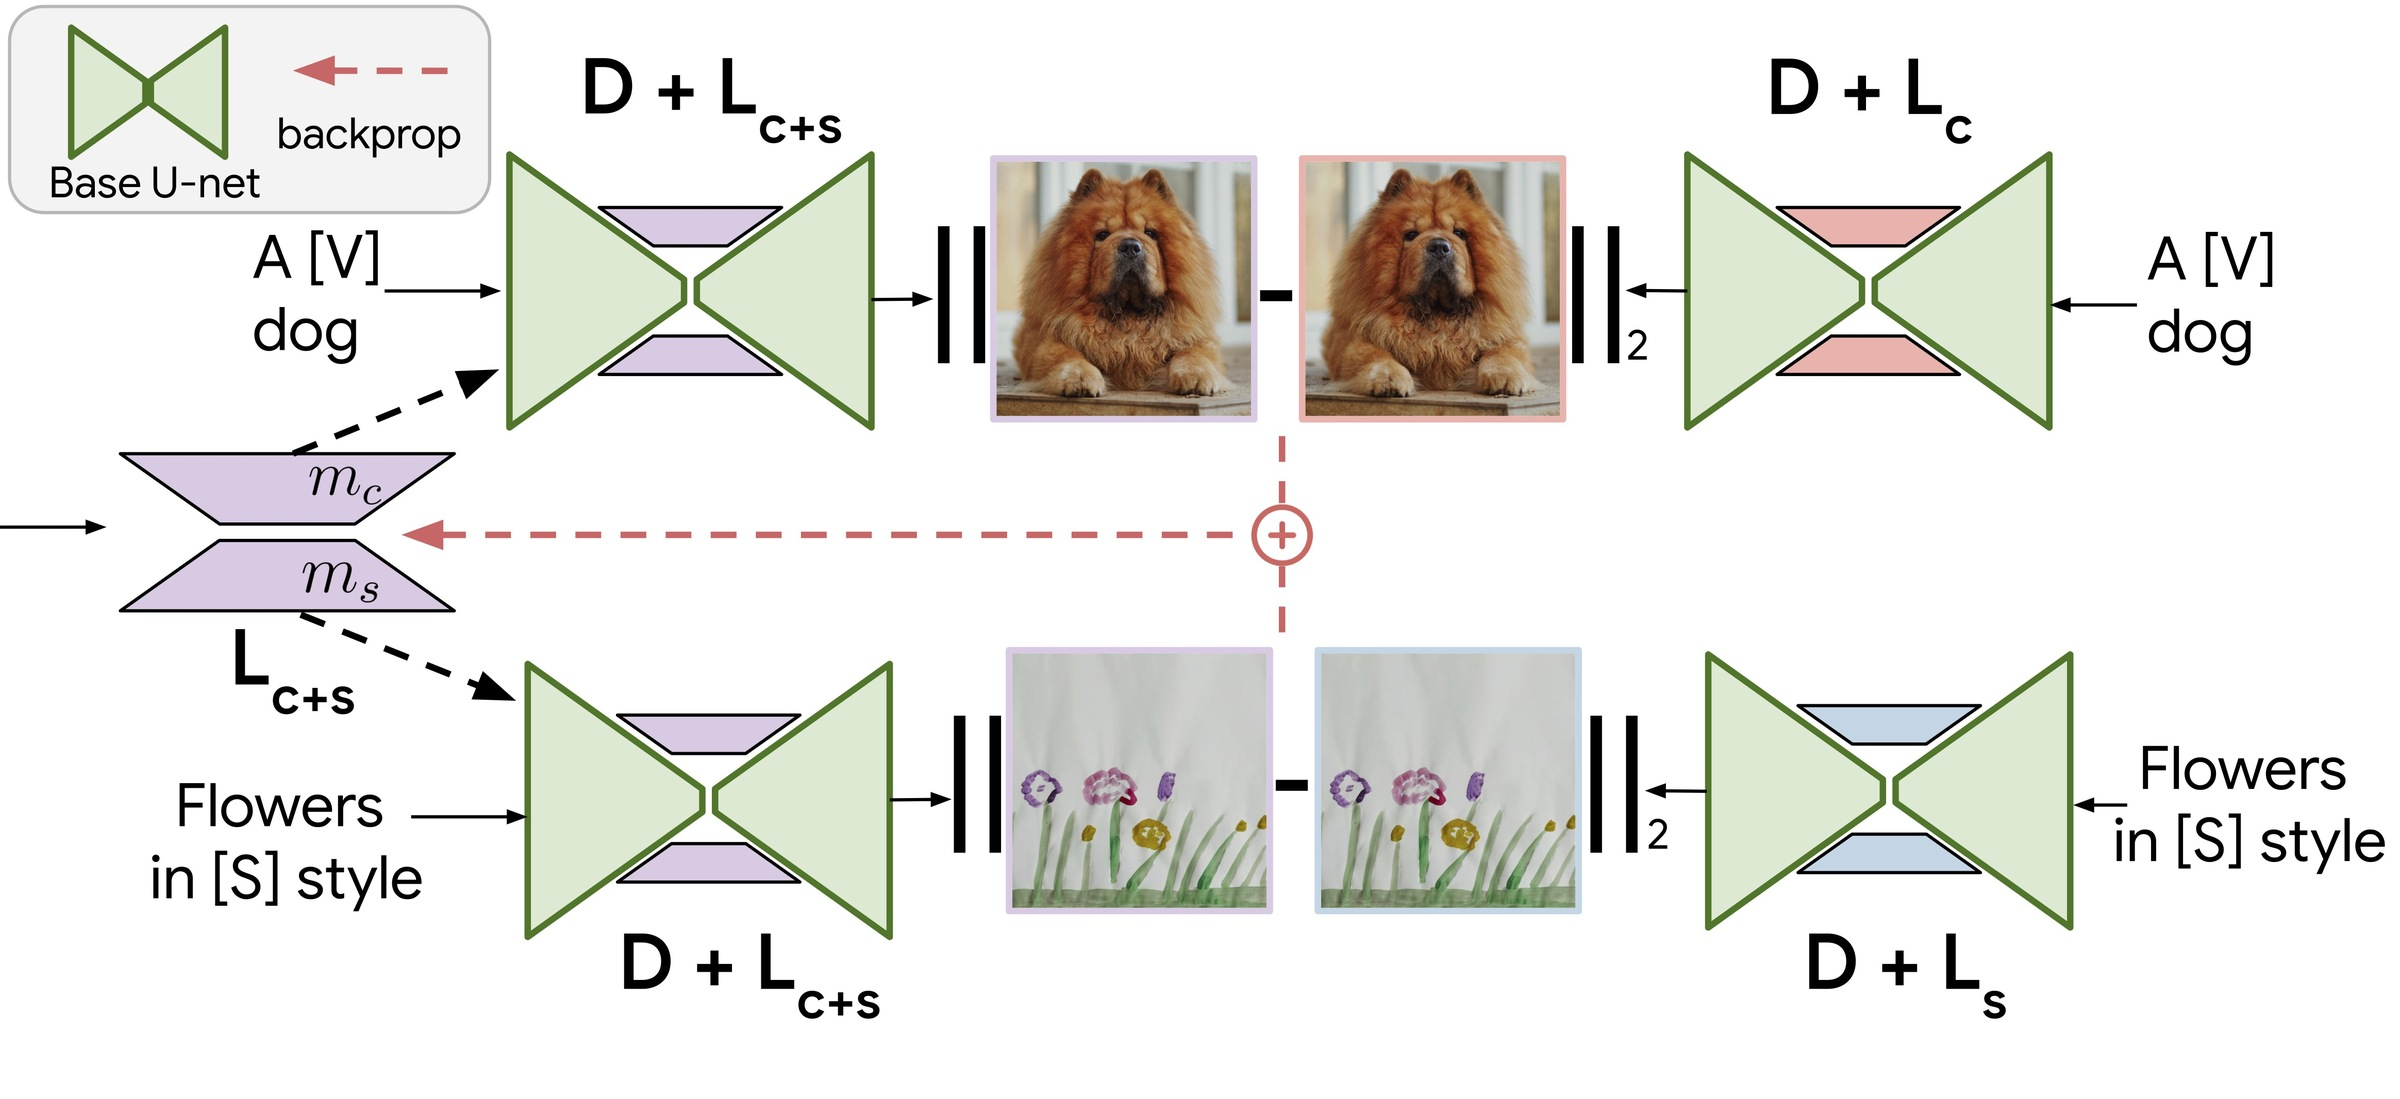

*Right part of the original scheme. Pictures illustrate model-output matching, not paired training targets.*

$$
\begin{aligned}\mathcal L_{\rm merge}={}&\|(D\oplus L_m)(x_c,p_c)-(D\oplus L_c)(x_c,p_c)\|_2\\&+\|(D\oplus L_m)(x_s,p_s)-(D\oplus L_s)(x_s,p_s)\|_2\\&+\lambda\sum_\ell\left|\left\langle m_c^{(\ell)},m_s^{(\ell)}\right\rangle\right|\end{aligned}
$$

<b>First two terms:</b> preserve each source adapter on its own condition.

<b>Last term:</b> penalize overlap between merger coefficients.

No ground-truth image of the subject in the new style is required.

**Takeaway:** Each pair of predictions shares its input. The subject and style terms use their respective inputs.

Sources: [Shah et al. · ZipLoRA v2 · Eq. 2–3](https://arxiv.org/html/2311.13600v2#S3)


## ZipLoRA: changing the amount of style

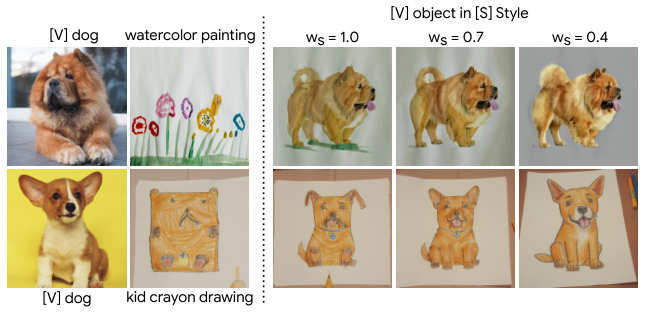

**Takeaway:** The extra style weight scales the learned style update. The merger is not retrained for each displayed value.

Sources: [Shah et al. · ZipLoRA](https://arxiv.org/abs/2311.13600)


## B-LoRA and ZipLoRA solve different problems

|  | B-LoRA | ZipLoRA |
| --- | --- | --- |
| Starting point | Reference image(s) | Two independently trained LoRAs |
| What learns | LoRA in selected SDXL groups | Per-column merger coefficients |
| How concepts combine | Select content and style groups | Reweight columns within each layer |
| Combining prepared adapters | Select groups; no new training | Optimize merger for each pair |
| Additional paired stylization data | Not required | Not required |
| Main limitation | Imperfect separation | Pair-specific optimization |

**Takeaway:** B-LoRA separates through block selection. ZipLoRA combines through learned merging.

Sources: [Frenkel et al. · B-LoRA](https://arxiv.org/abs/2403.14572) · [Shah et al. · ZipLoRA](https://arxiv.org/abs/2311.13600)


## ControlNet: a map specifies spatial structure

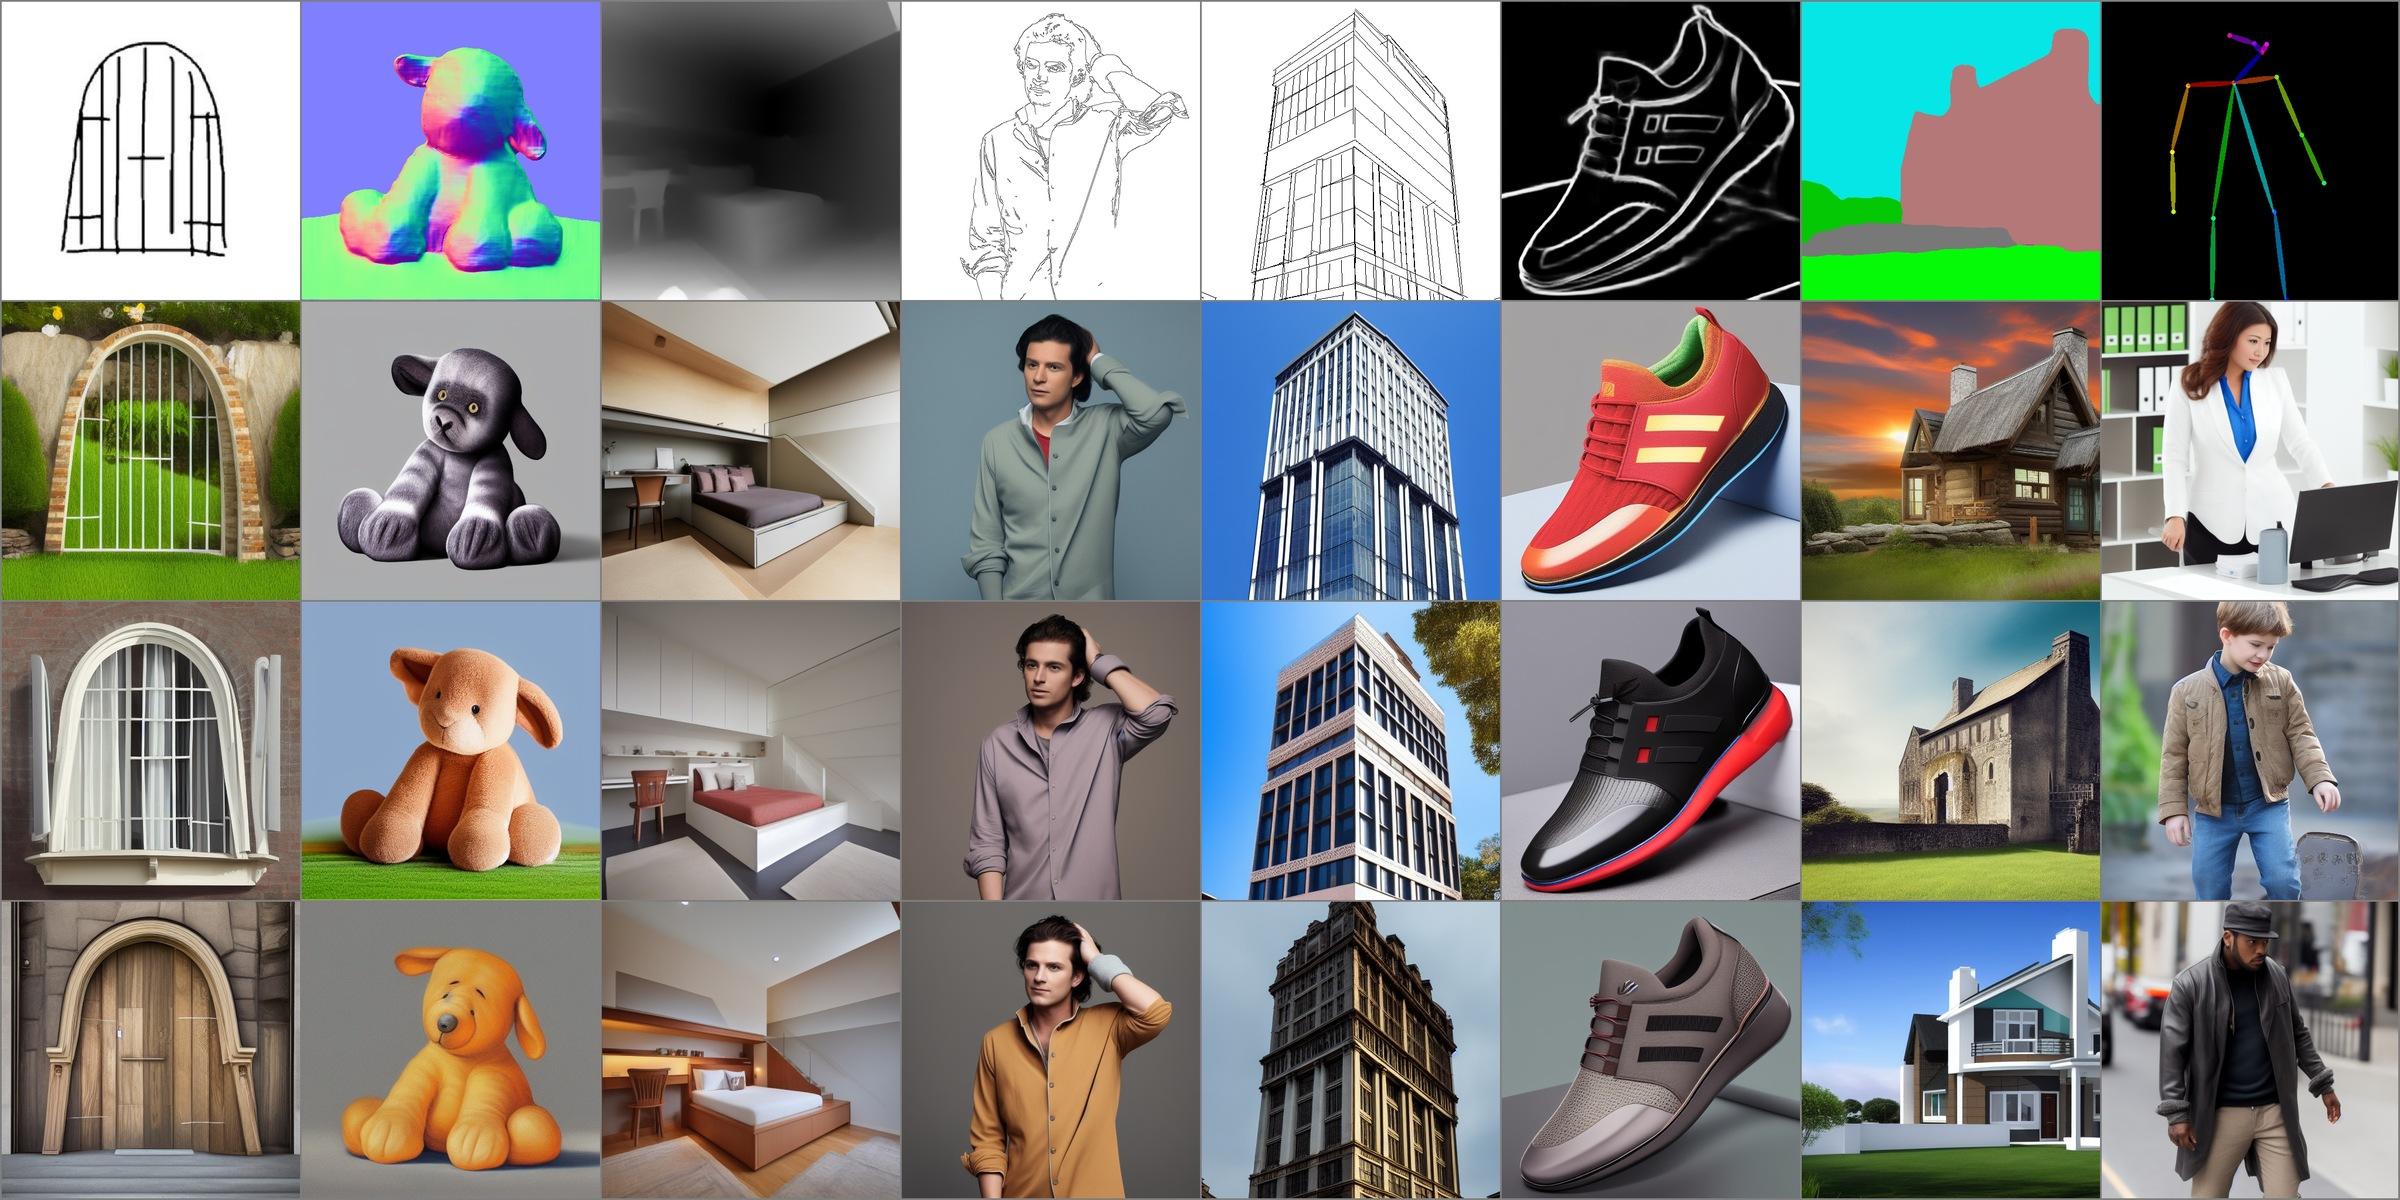

**Takeaway:** Top: control maps; below: outputs with empty text. Training drops 50% of text prompts to support this use.

Sources: [Zhang et al. · ControlNet](https://arxiv.org/abs/2302.05543)


## ControlNet: turn one frozen block into a controlled block

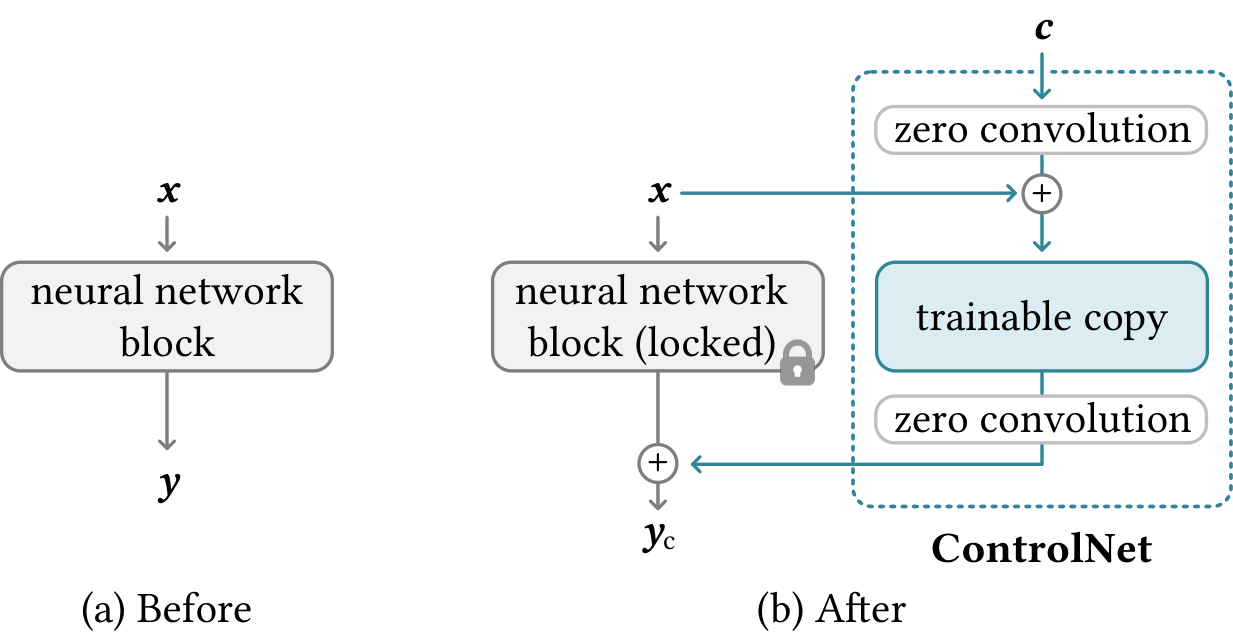

$$
y_c=F(x)+Z_{\rm out}\!\left(F_c\!\left(x+Z_{\rm in}(c)\right)\right)
$$

**Takeaway:** F is frozen; its copy F_c and both zero convolutions learn. Their initial residual contribution is zero.

Sources: [Zhang et al. · ControlNet](https://arxiv.org/abs/2302.05543)


## ControlNet architecture

**Encoder and middle: a trainable copy**

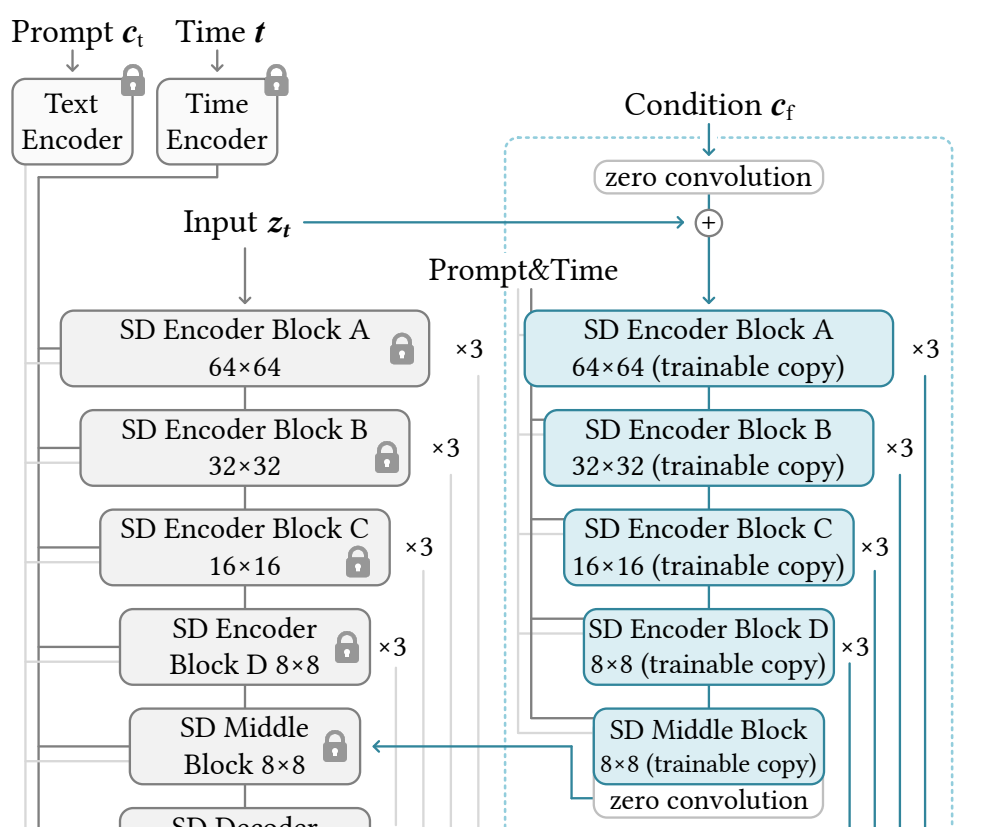

**Decoder: add zero-conv residuals**

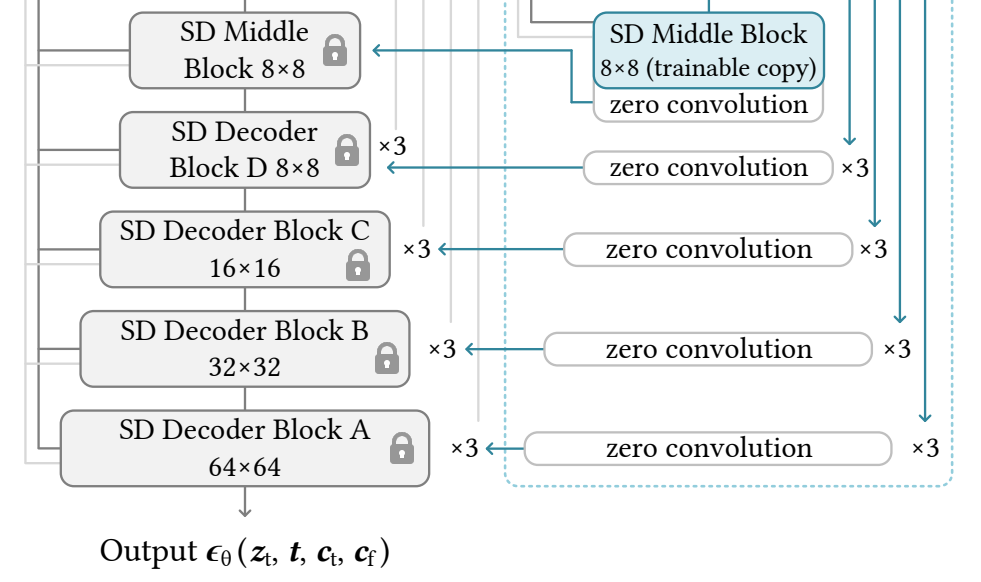

**Takeaway:** Two enlarged sections of Figure 3. Follow the copied encoder into the middle, then the residuals into decoder skips.

Sources: [Zhang et al. · ControlNet](https://arxiv.org/abs/2302.05543) · [ControlNet · official code](https://github.com/lllyasviel/ControlNet)


## Zero convolutions: zero output, nonzero learning

A 1×1 convolution applies $Z(h)=Wh+b$ at every location.

Example: $h=2$, target $=1$, $W=b=0$, loss $=\tfrac12(Wh+b-1)^2$.

$$
Z(h)=0,\qquad \frac{\partial\mathcal L}{\partial W}=(Wh+b-1)h=-2
$$

$$
\frac{\partial\mathcal L}{\partial h}=W(Wh+b-1)=0
$$

**Takeaway:** The output weight moves on the first update. Once W is nonzero, the control branch can receive gradients.

Sources: [Zhang et al. · ControlNet](https://arxiv.org/abs/2302.05543)


## ControlNet training data and loss

Encode the image-space map: $c_f=E(u)$, from 512×512 to 64×64 features.

Noise the VAE latent. Keep the condition map clean.

Replace 50% of text prompts with an empty string during training.

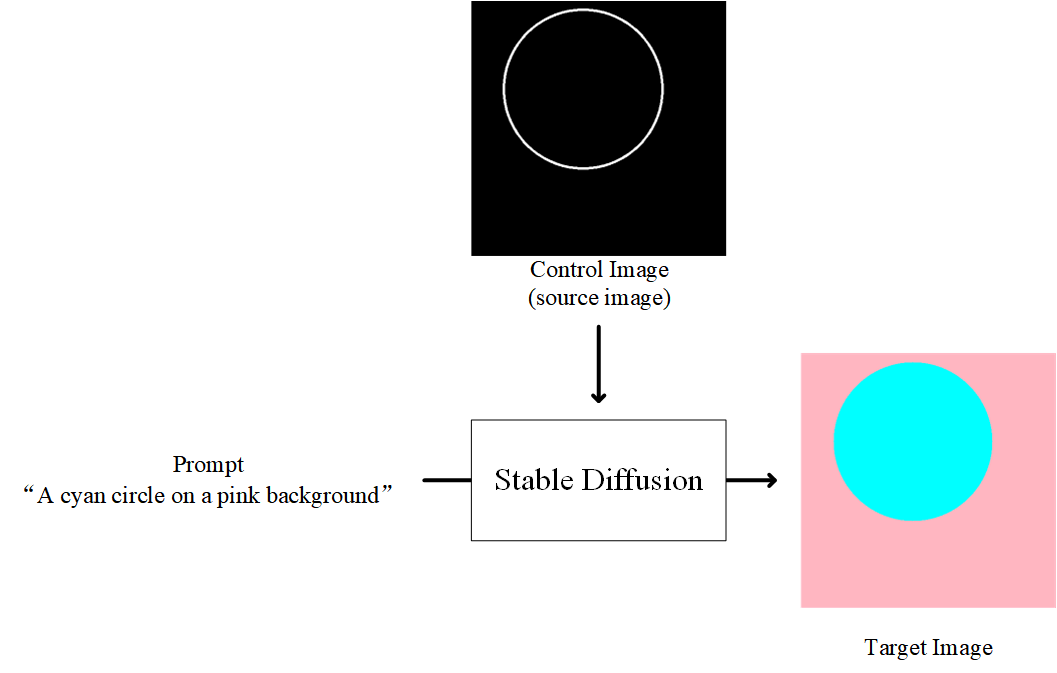

*Fill50K example from the official tutorial: contour + caption + target.*

$$
\mathcal L_{\rm CN}=\mathbb E\|\epsilon-\epsilon_{\theta,\phi}(z_t,t,c,E(u))\|_2^2
$$

<b>Data:</b> photo, caption and a map extracted from that same photo.

<b>Trainable:</b> condition encoder $E$, copied blocks and zero convolutions.

<b>Frozen:</b> the base U-Net and VAE.

**Takeaway:** Train the condition encoder and control branch. The target remains the sampled diffusion noise.

Sources: [Zhang et al. · ControlNet](https://arxiv.org/abs/2302.05543) · [ControlNet · official training tutorial](https://github.com/lllyasviel/ControlNet/blob/main/docs/train.md)


## ControlNet: when does the model follow the map?

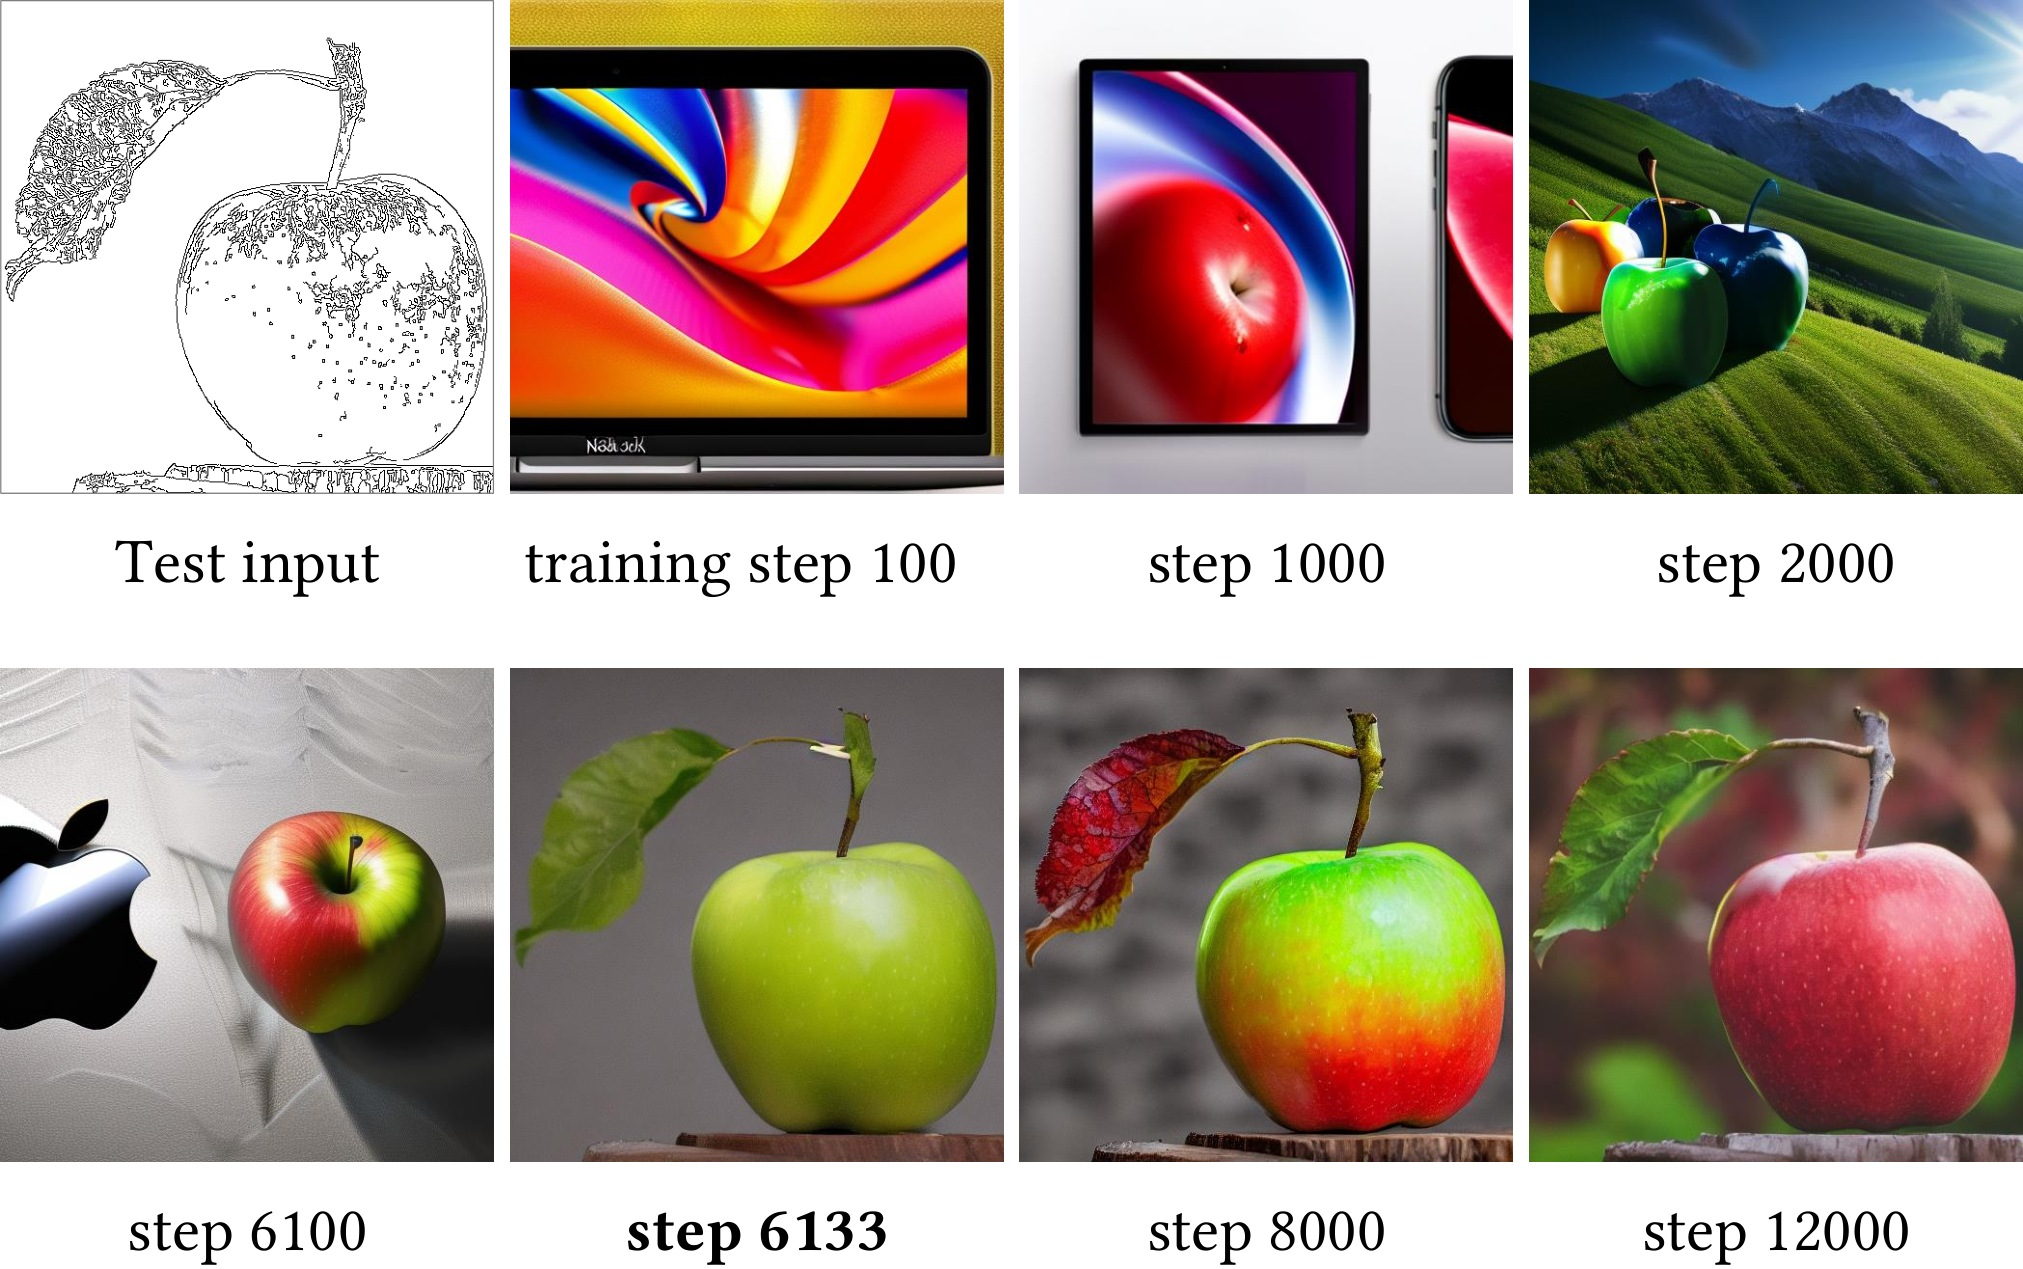

**Takeaway:** Image quality can appear before map adherence. Evaluate the control, not just the appearance.

Sources: [Zhang et al. · ControlNet](https://arxiv.org/abs/2302.05543)


## ControlNet: combining pose and depth

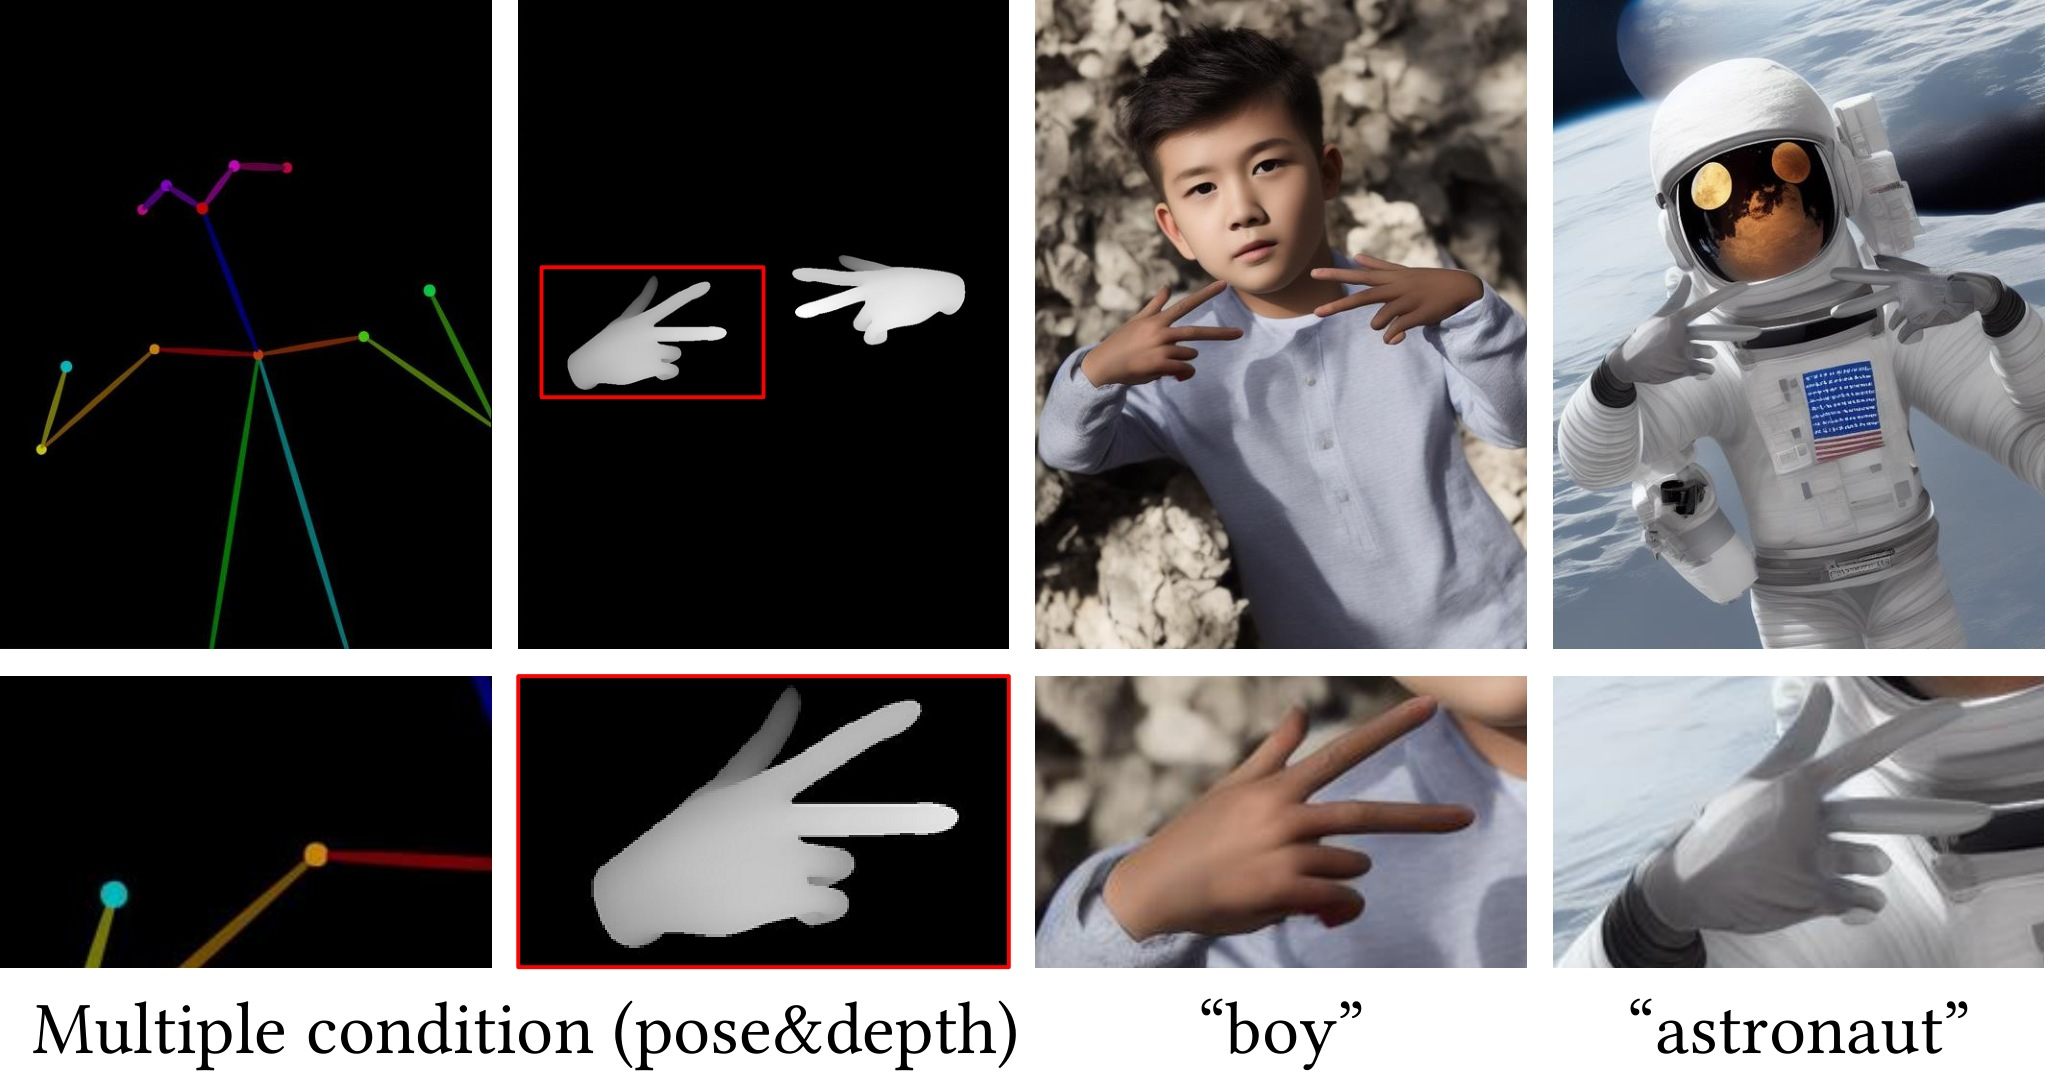

**Takeaway:** Figure 6: pose sets the body configuration; depth adds the hand geometry; text chooses “boy” or “astronaut”.

Sources: [Zhang et al. · ControlNet](https://arxiv.org/abs/2302.05543)


## IP-Adapter: an image becomes a prompt

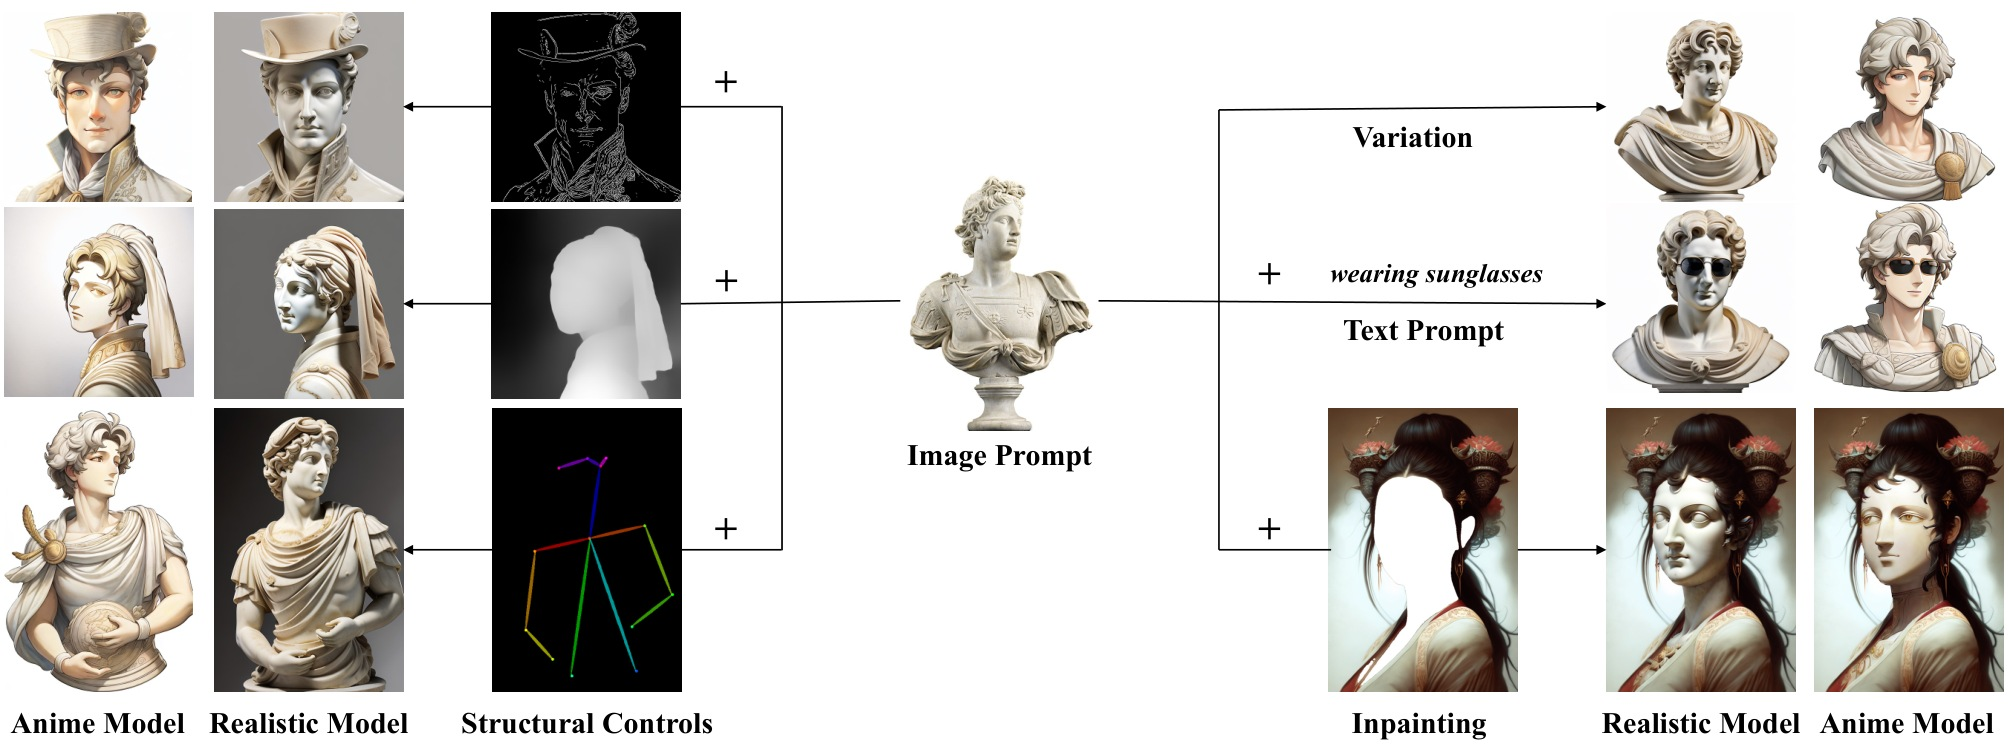

**Takeaway:** Figure 1: the same image prompt supports variations, text edits, inpainting and structural controls.

Sources: [Ye et al. · IP-Adapter](https://arxiv.org/abs/2308.06721)


## IP-Adapter: two attention outputs

$c_i$: four image tokens after Linear + LayerNorm; $d$: key/query dimension per head.

$Q=HW_q,\ K_t=c_tW_k,\ V_t=c_tW_v;\quad K_i=c_iW_k^{\prime},\ V_i=c_iW_v^{\prime}$.

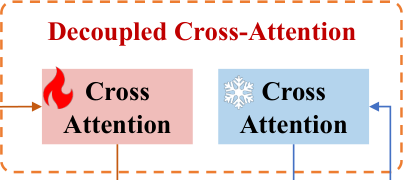

*Enlarged attention detail from the original architecture. Add the two outputs.*

$$
\begin{aligned}O_t&=\operatorname{softmax}\!\left(\frac{QK_t^\top}{\sqrt d}\right)V_t\\O_i&=\operatorname{softmax}\!\left(\frac{QK_i^\top}{\sqrt d}\right)V_i\end{aligned}
$$

$$
O=O_t+\lambda_{\rm IP}O_i
$$

$H$: current U-Net spatial features; $c_t$: text tokens.

Both branches read the same Q, but normalize their attention weights separately.

**Takeaway:** Initialize image W′k and W′v from text Wk and Wv. Only the image projections learn; Q is shared.

Sources: [Ye et al. · IP-Adapter](https://arxiv.org/abs/2308.06721)


## IP-Adapter: why separate the attention branches?

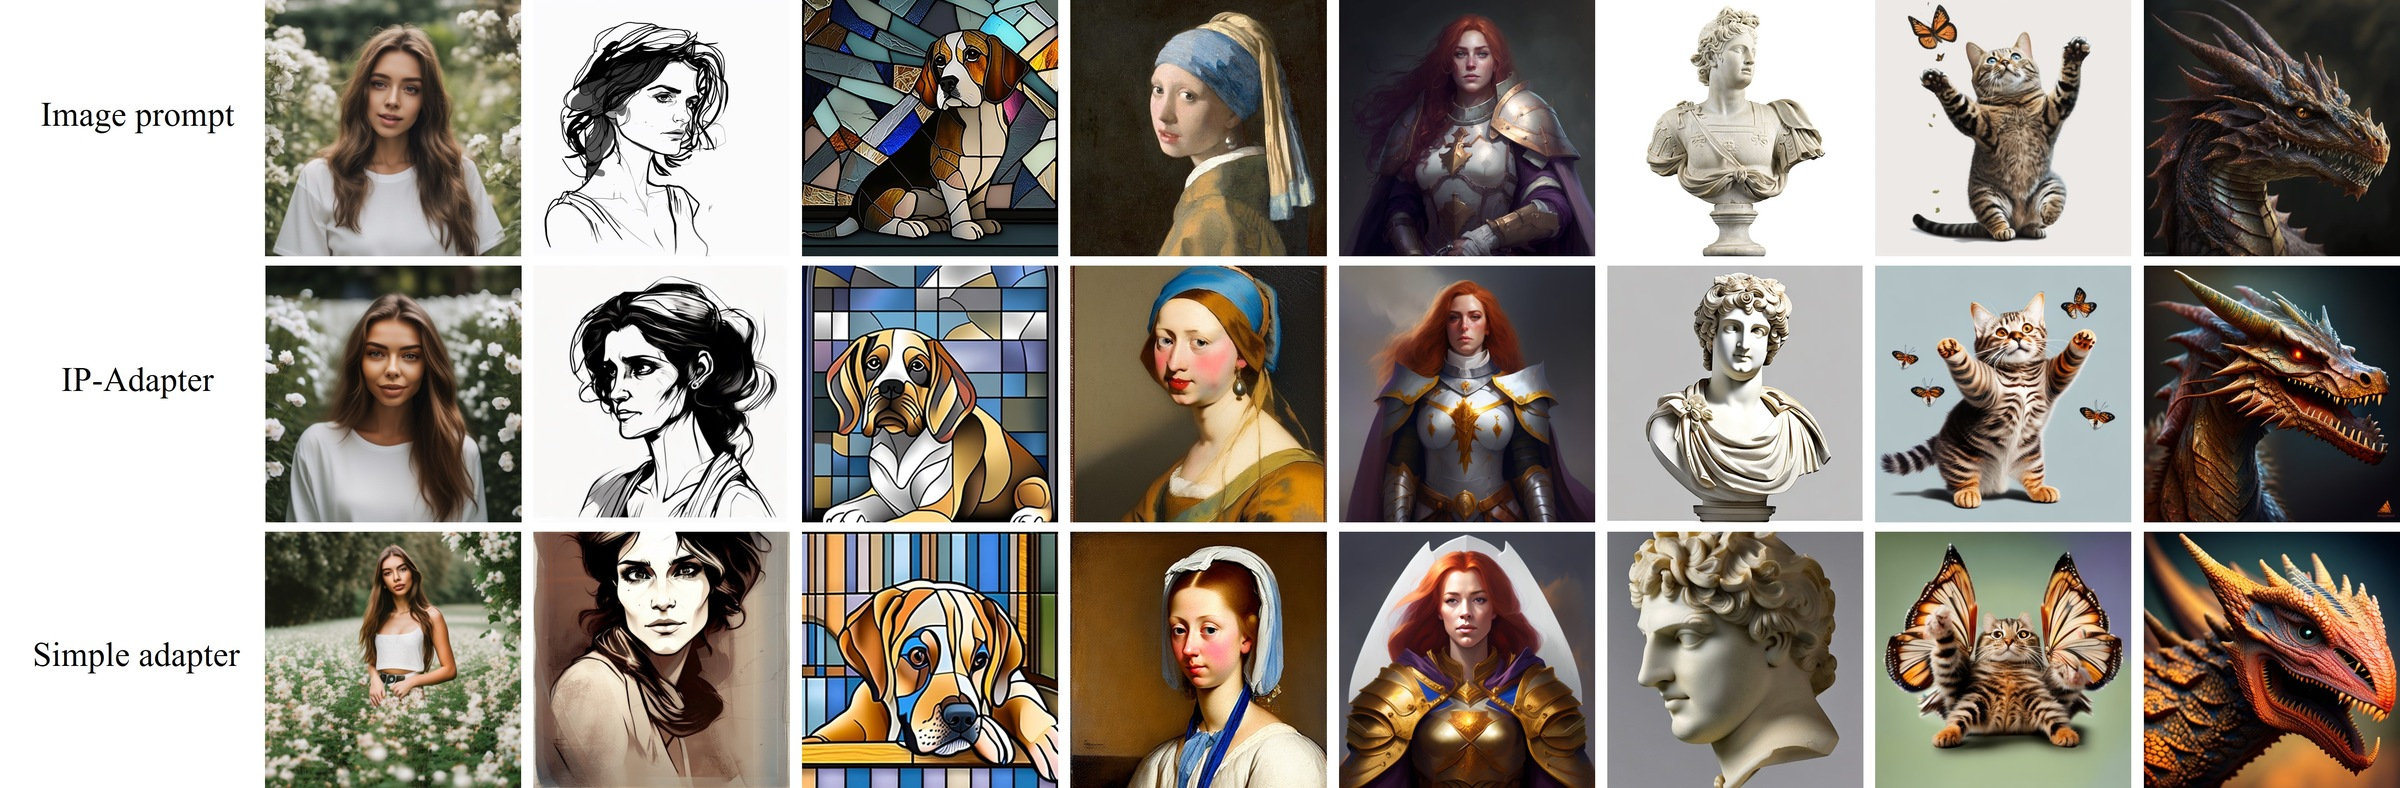

**Takeaway:** Figure 10: top row = image prompt, middle = IP-Adapter, bottom = a simple adapter without decoupled attention.

Sources: [Ye et al. · IP-Adapter](https://arxiv.org/abs/2308.06721)


## IP-Adapter training

Frozen OpenCLIP ViT-H/14 image encoder; projection produces 4 tokens.

Train the projection and image K/V: about 22M parameters in the SD 1.5 setup.



CFG training drops text only (5%), image only (5%), or both (5%).

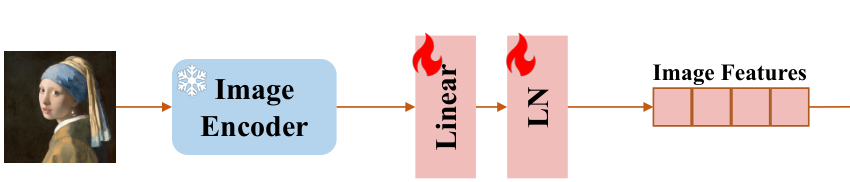

*Original image-conditioning path: frozen encoder, trainable projection, four tokens.*

$$
\mathcal L_{\rm IP}=\mathbb E\|\epsilon-\epsilon_{\theta,\phi}(z_t,t,c,P_\phi(E_{\rm image}(x)))\|_2^2
$$

**Takeaway:** Dropped image condition: zero CLIP embedding. CFG scale and image-attention weight λ are separate controls.

Sources: [Ye et al. · IP-Adapter](https://arxiv.org/abs/2308.06721) · [IP-Adapter · official code](https://github.com/tencent-ailab/IP-Adapter)


## Image and text can request different things

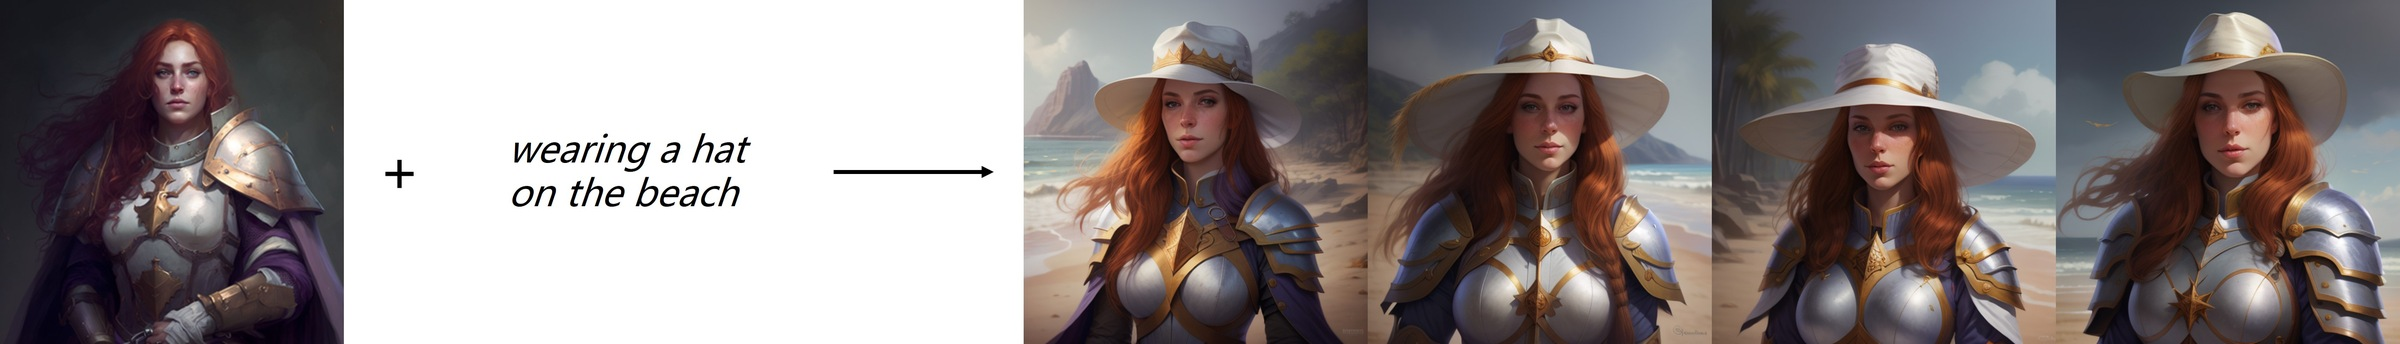

**Takeaway:** Inspect which details follow the reference and which follow the text.

Sources: [IP-Adapter · official code](https://github.com/tencent-ailab/IP-Adapter)


## Two reference types in one generation

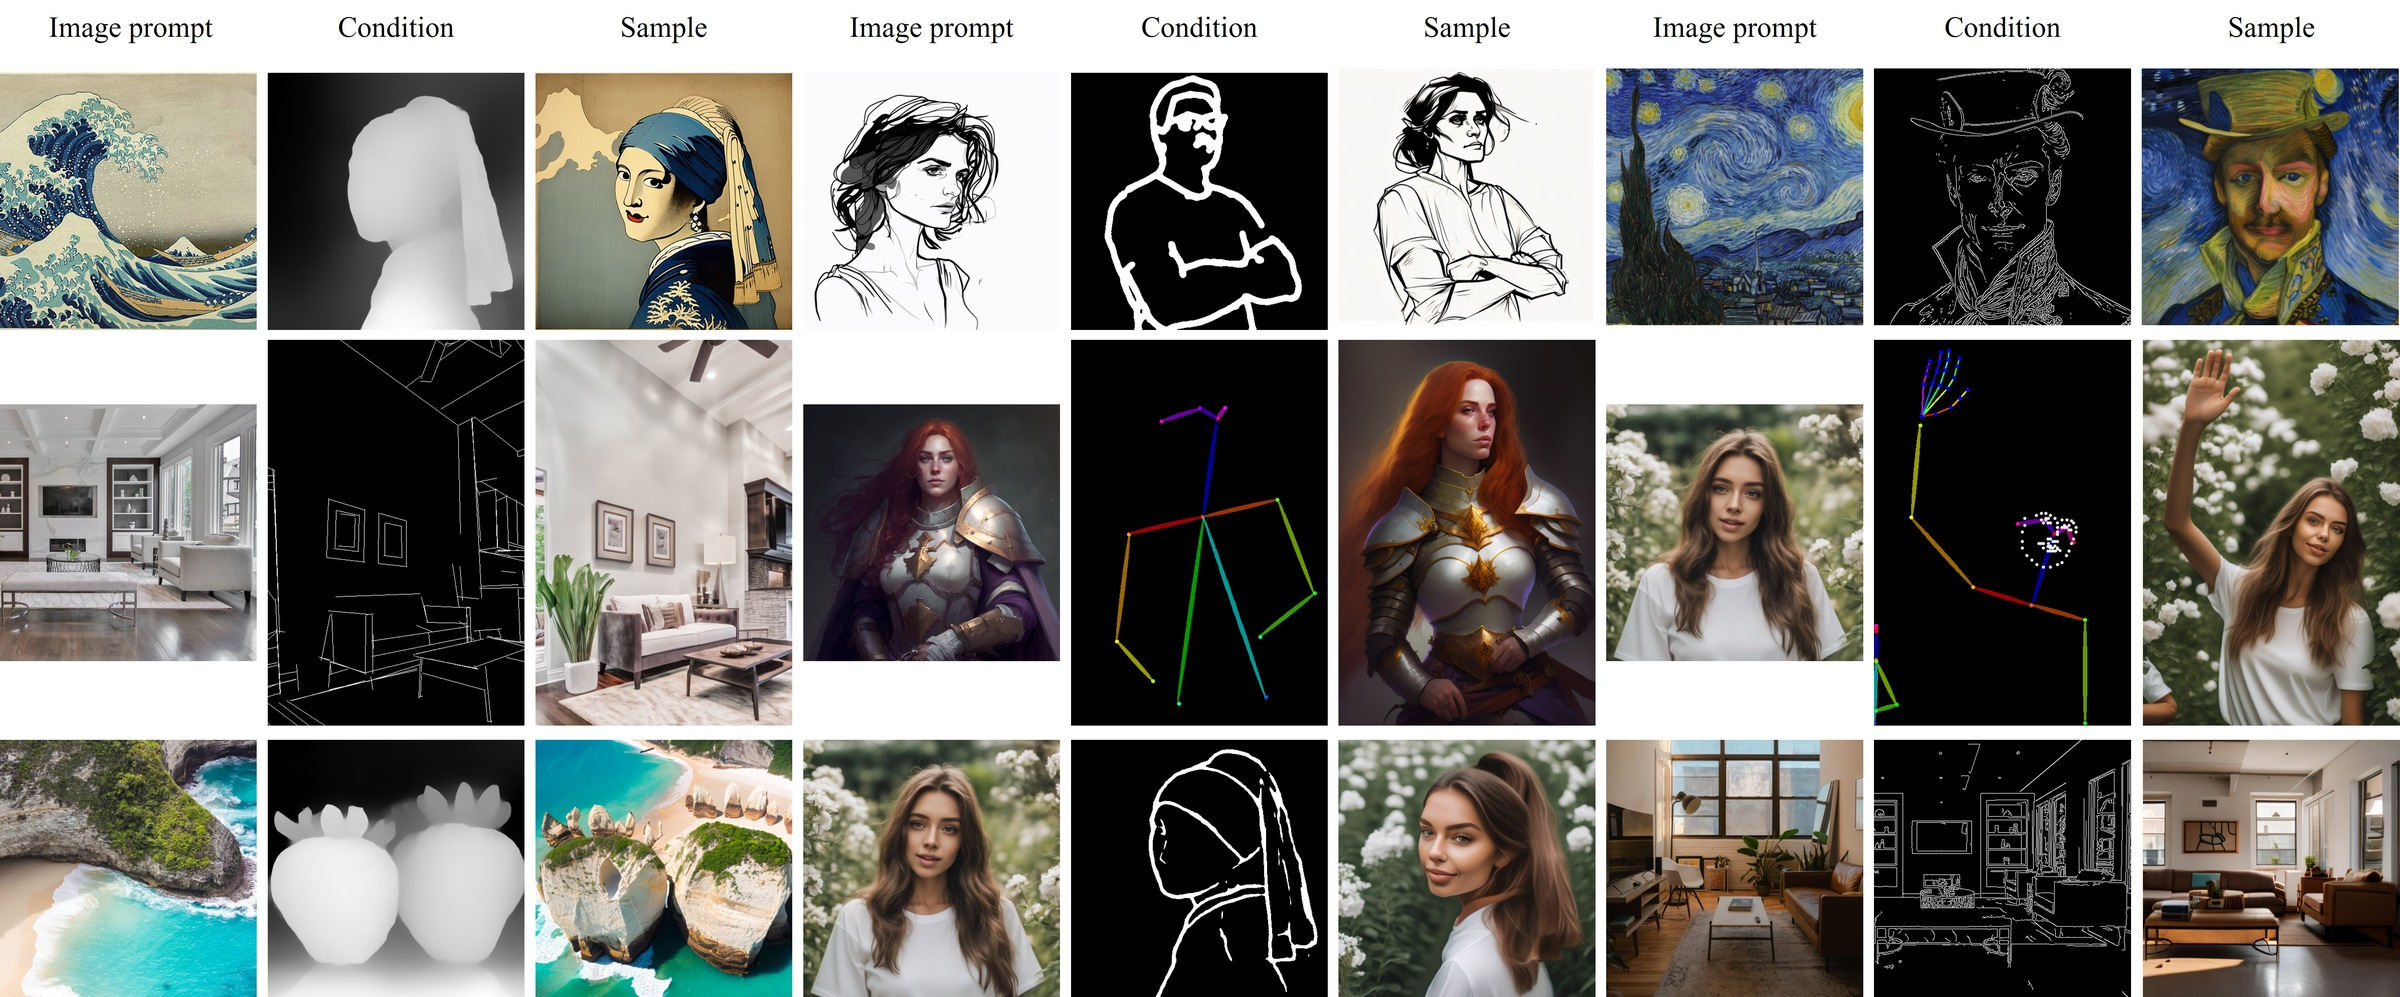

**Takeaway:** Read each triplet as image prompt → structural condition → generated sample.

Sources: [Ye et al. · IP-Adapter](https://arxiv.org/abs/2308.06721)


## Five controls with different meanings

| Parameter | Where it acts | What it changes |
| --- | --- | --- |
| CFG scale | Conditional/unconditional predictions | Overall conditional extrapolation |
| LoRA scale | W₀ + a(α/r)BA | Influence of learned adaptation |
| ControlNet scale γ | Diffusers: controlnet_conditioning_scale | Scales added spatial residuals |
| IP-Adapter scale λ | Image attention output | Influence of visual reference |
| img2img strength | Initial noise level | How much of a source image is replaced |

**Takeaway:** These coefficients are not interchangeable and do not share a universal useful range.

Sources: [Diffusers v0.35.1 · IP-Adapter](https://huggingface.co/docs/diffusers/v0.35.1/en/using-diffusers/ip_adapter)


## Practice: controlled comparisons

| Experiment | Fixed | Varied |
| --- | --- | --- |
| ControlNet | Noise, prompt, map, sampler | γ = 0, 0.5, 1.0 |
| IP-Adapter | Noise, prompt, reference, sampler | λ = 0, 0.5, 1.0 |
| Combined control | Noise, prompt, both inputs | 2 × 2 grid of γ and λ |
| LoRA arithmetic | Frozen toy base and updates | Scale, rank and merger coefficients |

**Takeaway:** Repeat with several seeds. Judge identity, style, layout and text adherence separately.



## Which method fits the request?

| Method | Per-reference optimization? | What is stored or passed? |
| --- | --- | --- |
| DreamBooth + LoRA | Yes | Subject-specific adapter weights |
| B-LoRA | Yes, for each reference | Selected content/style block updates |
| ZipLoRA | Two prepared LoRAs + merger per pair | Merger coefficients / merged update |
| ControlNet | No, with pretrained control model | Aligned spatial map |
| IP-Adapter | No, with pretrained image adapter | Reference image tokens |

**Takeaway:** Choose the condition and the training budget before choosing the adapter.

Sources: [Ruiz et al. · DreamBooth](https://arxiv.org/abs/2208.12242) · [Frenkel et al. · B-LoRA](https://arxiv.org/abs/2403.14572) · [Shah et al. · ZipLoRA](https://arxiv.org/abs/2311.13600) · [Zhang et al. · ControlNet](https://arxiv.org/abs/2302.05543) · [Ye et al. · IP-Adapter](https://arxiv.org/abs/2308.06721)


## Takeaways

DreamBooth learns a subject; LoRA constrains the rank of the weight update ΔW = BA.



B-LoRA selects specialized block groups; ZipLoRA learns a merge of existing updates.



ControlNet injects spatial residuals; IP-Adapter adds image-conditioned attention.



Compare controls with fixed noise, multiple seeds and separate evaluation axes.

**Takeaway:** For every method: name the input, trainable parameters, target and sampling path.



## Practice A · adapter mechanics on CPU
These small experiments test the mathematics without downloading diffusion weights. They are **not image-generation benchmarks**. Run them before the GPU section.


In [1]:
import numpy as np
rng = np.random.default_rng(2026)
d_in, d_out, rank = 16, 12, 3
W0 = rng.normal(size=(d_out, d_in))
A = rng.normal(size=(rank, d_in))
B = rng.normal(size=(d_out, rank))
x = rng.normal(size=(d_in, 5))
scale = 0.7
branch = W0 @ x + scale * (B @ (A @ x))
merged = (W0 + scale * B @ A) @ x
print("Branch / merged maximum error:", np.max(np.abs(branch - merged)))
print("Full weight parameters:", W0.size, "LoRA parameters:", A.size + B.size)
assert np.allclose(branch, merged)


Branch / merged maximum error: 3.608224830031759e-15
Full weight parameters: 192 LoRA parameters: 84


### A column merger is not a rank-component merger
For $\Delta W=BA$, scaling its input columns gives $\Delta W\,\mathrm{diag}(m)=B(A\,\mathrm{diag}(m))$. The following matrix identity is the arithmetic used by a column merger. It does not reproduce ZipLoRA's full diffusion optimization.


In [2]:
Ac, As = rng.normal(size=(rank, d_in)), rng.normal(size=(rank, d_in))
Bc, Bs = rng.normal(size=(d_out, rank)), rng.normal(size=(d_out, rank))
mc, ms = rng.uniform(size=d_in), rng.uniform(size=d_in)
delta_c, delta_s = Bc @ Ac, Bs @ As
weighted = delta_c * mc[None, :] + delta_s * ms[None, :]
concatenated = np.concatenate([Bc, Bs], axis=1) @ np.concatenate(
    [Ac * mc[None, :], As * ms[None, :]], axis=0)
assert np.allclose(weighted, concatenated)
print("Original rank bound:", rank, "Merged rank bound:", 2 * rank)
print("Merger coefficients per matrix:", mc.size + ms.size)
print("Coefficient overlap:", abs(mc @ ms))
# Try disjoint masks. Observe that zero overlap alone can discard useful behavior.
mc[:d_in//2], mc[d_in//2:] = 1, 0
ms[:d_in//2], ms[d_in//2:] = 0, 1
print("Disjoint-mask overlap:", abs(mc @ ms))


Original rank bound: 3 Merged rank bound: 6
Merger coefficients per matrix: 32
Coefficient overlap: 5.635808424868407
Disjoint-mask overlap: 0.0


### Why zero convolution can learn
A single location is enough: $Z(h)=Wh+b$. At initialization the output is zero, but the derivative with respect to $W$ need not be zero. The derivative into the branch features is initially zero through this connection.


In [3]:
h = rng.normal(size=5)
target = rng.normal(size=3)
W, b = np.zeros((3, 5)), np.zeros(3)
error = W @ h + b - target
# L = 0.5 * ||Z(h) - target||^2
grad_W, grad_h = np.outer(error, h), W.T @ error
step = 1e-6
Wp = W.copy(); Wp[0, 0] += step
Wm = W.copy(); Wm[0, 0] -= step
loss = lambda w: 0.5 * np.sum((w @ h + b - target)**2)
finite_difference = (loss(Wp) - loss(Wm)) / (2 * step)
assert np.isclose(finite_difference, grad_W[0, 0])
print("Output at initialization:", W @ h + b)
print("Weight gradient norm:", np.linalg.norm(grad_W))
print("Feature gradient norm:", np.linalg.norm(grad_h))
W -= 0.01 * grad_W
print("Feature gradient after one weight update:", np.linalg.norm(W.T @ (W @ h - target)))


Output at initialization: [0. 0. 0.]
Weight gradient norm: 5.74587469443167
Feature gradient norm: 0.0
Feature gradient after one weight update: 0.20051324888902966


### Two softmax operations in IP-Adapter
Check that image scale zero recovers text attention and that scale one still retains the text term.


In [4]:
def attention(q, k, v):
    logits = q @ k.T / np.sqrt(q.shape[-1])
    logits -= logits.max(axis=-1, keepdims=True)
    weights = np.exp(logits); weights /= weights.sum(axis=-1, keepdims=True)
    return weights @ v
Q = rng.normal(size=(5, 8))
Kt, Vt = rng.normal(size=(7, 8)), rng.normal(size=(7, 8))
Ki, Vi = rng.normal(size=(4, 8)), rng.normal(size=(4, 8))
Ot, Oi = attention(Q, Kt, Vt), attention(Q, Ki, Vi)
assert np.allclose(Ot + 0 * Oi, Ot)
print("At image scale 1, text contribution norm:", np.linalg.norm((Ot + Oi) - Oi))
concat_output = attention(Q, np.concatenate([Kt, Ki]), np.concatenate([Vt, Vi]))
print("Difference from concatenating conditions:", np.linalg.norm(Ot + Oi - concat_output))


At image scale 1, text contribution norm: 2.6586886750049614
Difference from concatenating conditions: 3.0957354162649726


## Practice B · ControlNet and IP-Adapter in Colab
Choose **Runtime → Change runtime type → GPU**. The lab uses one SD 1.5 base with compatible Canny ControlNet and IP-Adapter checkpoints, at 512×512. SDXL/B-LoRA use a separate environment below.

The GPU experiments are **prepared but not precomputed**. Set `RUN_GPU = True`, then run the installation and following cells. Model downloads require network access and several GB of disk space. GPU memory and runtime depend on the assigned hardware.

The initial reference comes from the public Diffusers documentation. You can replace it with your own image. The base safety checker remains enabled.


In [ ]:
RUN_GPU = False
if RUN_GPU:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "diffusers==0.35.1", "transformers==4.49.0", "accelerate==1.10.1",
        "peft==0.17.1", "safetensors>=0.4.3", "opencv-python-headless",
        "matplotlib", "Pillow"])
else:
    print("GPU lab disabled. Set RUN_GPU=True in this cell to begin.")


In [ ]:
if RUN_GPU:
    import gc, json, time
    from pathlib import Path
    import torch, cv2
    import matplotlib.pyplot as plt
    from PIL import Image
    from diffusers import ControlNetModel, StableDiffusionControlNetPipeline, DDIMScheduler
    from diffusers.utils import load_image
    assert torch.cuda.is_available(), "Select a GPU runtime in Colab."
    BASE = "stable-diffusion-v1-5/stable-diffusion-v1-5"
    CN = "lllyasviel/control_v11p_sd15_canny"
    controlnet = ControlNetModel.from_pretrained(CN, torch_dtype=torch.float16)
    pipe = StableDiffusionControlNetPipeline.from_pretrained(
        BASE, controlnet=controlnet, torch_dtype=torch.float16)
    pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
    pipe.enable_model_cpu_offload()
    pipe.enable_vae_slicing()
    OUTPUT = Path("seminar10_outputs"); OUTPUT.mkdir(exist_ok=True)
    SEED, STEPS, CFG = 2026, 25, 7.5
    url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/input_image_vermeer.png"
    # Use one documented image as a reproducible default; update the prompt accordingly.
    source_image = load_image(url).convert("RGB").resize((512, 512))
    PROMPT = "a watercolor portrait of a woman wearing a blue headscarf, warm light, textured paper"
    gray = cv2.cvtColor(np.asarray(source_image), cv2.COLOR_RGB2GRAY)
    edges = Image.fromarray(cv2.Canny(gray, 100, 200)).convert("RGB")
    source_image.save(OUTPUT / "reference.png"); edges.save(OUTPUT / "canny.png")
    def show_images(images, labels, columns=None):
        columns = columns or len(images)
        rows = (len(images) + columns - 1) // columns
        fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4.5 * rows), facecolor="white")
        flat = np.atleast_1d(axes).ravel()
        for ax, im, label in zip(flat, images, labels):
            ax.imshow(im); ax.set_title(label); ax.axis("off")
        for ax in flat[len(images):]:
            ax.axis("off")
        plt.tight_layout(); plt.show()
    show_images([source_image, edges], ["Reference", "Canny condition"])


### ControlNet scale sweep
The generator is reset for **every** image. Scale 0 keeps the ControlNet loaded but removes its residual contribution. Start from Gaussian noise at every scale; this is not img2img strength.


In [ ]:
if RUN_GPU:
    results, records = [], []
    for gamma in [0.0, 0.5, 1.0]:
        generator = torch.Generator(device="cpu").manual_seed(SEED)
        started = time.perf_counter()
        result = pipe(PROMPT, image=edges, height=512, width=512,
            num_inference_steps=STEPS, guidance_scale=CFG, eta=0.0,
            controlnet_conditioning_scale=gamma, generator=generator).images[0]
        result.save(OUTPUT / f"control_{gamma:.1f}.png"); results.append(result)
        records.append(dict(kind="controlnet", gamma=gamma, seed=SEED,
                            seconds=time.perf_counter()-started))
    show_images(results, ["ControlNet = 0", "ControlNet = 0.5", "ControlNet = 1"])


### IP-Adapter sweep on the same base
Load the image adapter once, then set ControlNet scale to 0. IP scale 1 retains text attention. Inspect the headscarf, pose, palette and background separately.


In [ ]:
if RUN_GPU:
    pipe.load_ip_adapter("h94/IP-Adapter", subfolder="models", weight_name="ip-adapter_sd15.bin")
    ip_results = []
    for image_scale in [0.0, 0.5, 1.0]:
        pipe.set_ip_adapter_scale(image_scale)
        result = pipe(PROMPT, image=edges, ip_adapter_image=source_image,
            height=512, width=512, num_inference_steps=STEPS, guidance_scale=CFG,
            eta=0.0, controlnet_conditioning_scale=0.0,
            generator=torch.Generator(device="cpu").manual_seed(SEED)).images[0]
        result.save(OUTPUT / f"ip_{image_scale:.1f}.png"); ip_results.append(result)
        records.append(dict(kind="ip_adapter", image_scale=image_scale, gamma=0.0, seed=SEED))
    show_images(ip_results, ["IP = 0", "IP = 0.5", "IP = 1"])


### Combine layout and visual reference
The first grid uses the same photograph for both conditions so the requests agree. Then replace **only** `appearance_reference` with a second image and repeat: can the model obey a new appearance while retaining the original Canny layout?


In [ ]:
if RUN_GPU:
    appearance_reference = source_image
    combined, labels = [], []
    for gamma, image_scale in [(0.0, 0.0), (1.0, 0.0), (0.0, 0.8), (1.0, 0.8)]:
        pipe.set_ip_adapter_scale(image_scale)
        result = pipe(PROMPT, image=edges, ip_adapter_image=appearance_reference,
            height=512, width=512, num_inference_steps=STEPS, guidance_scale=CFG,
            controlnet_conditioning_scale=gamma, eta=0.0,
            generator=torch.Generator(device="cpu").manual_seed(SEED)).images[0]
        result.save(OUTPUT / f"combined_cn{gamma}_ip{image_scale}.png")
        combined.append(result); labels.append(f"CN={gamma}, IP={image_scale}")
        records.append(dict(kind="combined", gamma=gamma, image_scale=image_scale, seed=SEED))
    show_images(combined, labels, columns=2)
    metadata = dict(base=BASE, controlnet=CN, ip_adapter="h94/IP-Adapter/models/ip-adapter_sd15.bin",
                    prompt=PROMPT, seed=SEED, steps=STEPS, cfg=CFG,
                    scheduler=pipe.scheduler.__class__.__name__, experiments=records)
    (OUTPUT / "parameters.json").write_text(json.dumps(metadata, indent=2))


**Questions.** Which result best follows the pose? Which copies appearance? Which obeys the text? Repeat with seeds 7, 42 and 2026 before drawing a conclusion. More control can also preserve unwanted edges or copy an unwanted background.

## Practice C · DreamBooth, B-LoRA and ZipLoRA
Training a personal adapter is a separate preparation task. Keep the reference images, class prompt, base checkpoint, seed and training configuration with each adapter. Full training is not run automatically by this notebook.

### DreamBooth + LoRA: reproducible training entry point
Use the [Diffusers DreamBooth example](https://github.com/huggingface/diffusers/tree/v0.35.1/examples/dreambooth) in a separate GPU session. Prepare a directory with several views of one subject; the directory `class_images` will hold generic class images. This command is a **starting recipe**, not a guarantee of convergence or a paper reproduction. Compare checkpoints and tune the step count for your photos.

```bash
git clone --branch v0.35.1 --depth 1 https://github.com/huggingface/diffusers.git
pip install -e ./diffusers
pip install -r diffusers/examples/dreambooth/requirements.txt
accelerate launch diffusers/examples/dreambooth/train_dreambooth_lora.py \
  --pretrained_model_name_or_path=stable-diffusion-v1-5/stable-diffusion-v1-5 \
  --instance_data_dir=subject_images --class_data_dir=class_images \
  --output_dir=subject_lora --instance_prompt="a photo of sks dog" \
  --class_prompt="a photo of a dog" --with_prior_preservation \
  --prior_loss_weight=1.0 --num_class_images=100 --resolution=512 \
  --rank=8 --train_batch_size=1 --gradient_accumulation_steps=1 \
  --learning_rate=1e-4 --lr_scheduler=constant --lr_warmup_steps=0 \
  --max_train_steps=800 --checkpointing_steps=200 --seed=2026 \
  --mixed_precision=fp16 --gradient_checkpointing
```

Load the resulting adapter into the **same base**, use `sks dog` in new prompts, and also evaluate `a dog` without `sks`. This does not train a new token embedding unless explicitly configured.

### B-LoRA: inspect exactly which blocks are selected
[Official B-LoRA Colab](https://colab.research.google.com/github/yardenfren1996/B-LoRA/blob/main/B_LoRA_inference.ipynb) · [Official training instructions](https://github.com/yardenfren1996/B-LoRA)

The authors' original training environment uses Diffusers 0.25.0 without PEFT. Keep it separate from the ControlNet/IP-Adapter environment above. Their example uses `lora-library/B-LoRA-teddybear` and `lora-library/B-LoRA-pen_sketch`, with prompt `A [v18] in [v30] style`.

The following CPU exercise checks filtering logic only. It does not load a model or fabricate generated images.


In [5]:
content_key = "unet.up_blocks.0.attentions.0"
style_key = "unet.up_blocks.0.attentions.1"
example_A = {content_key + ".to_q.lora.down.weight": "content A",
             style_key + ".to_q.lora.down.weight": "style A"}
example_B = {content_key + ".to_q.lora.down.weight": "content B",
             style_key + ".to_q.lora.down.weight": "style B"}
selected = {k: v for k, v in example_A.items() if content_key in k}
selected.update({k: v for k, v in example_B.items() if style_key in k})
print(selected)
assert set(selected.values()) == {"content A", "style B"}


{'unet.up_blocks.0.attentions.0.to_q.lora.down.weight': 'content A', 'unet.up_blocks.0.attentions.1.to_q.lora.down.weight': 'style B'}


**B-LoRA experiment:** generate content-only, style-only and the mixed pair at the same seed. Keep the block selection fixed and change the prompt. Check whether style also brings unwanted object shape.

**ZipLoRA experiment:** compare subject-only, style-only, direct merge and the optimized merger on the same base and initial latent. The [paper and project](https://ziplora.github.io/) are the reference; do not label an ordinary two-scale adapter mixture as ZipLoRA. The CPU column-merger exercise above demonstrates the arithmetic, not the full optimization.

**Discussion:** a scalar multiplier does not rotate a nonzero column. The overlap term encourages selection/suppression of competing contributions; preservation terms prevent a trivial all-zero merge. Low rank alone does not imply sparse entries.

## Run status
CPU mechanics are executed and their outputs saved during preparation. GPU model downloads, full adapter training and generated-image sweeps require a GPU runtime and are not claimed as completed here. Figures in the theory section are attributed author figures or original explanatory diagrams.
